# Phase 4: Model Evaluation of the Movie Recommender
**Evaluates the Phase 3 model** (tuned SVD, with item-based KNN as runner-up) **on Phase 2's held-out `test.csv`.**

## Executive summary

| Question | Finding |
|---|---|
| **Does it predict ratings better than naive benchmarks?** | **Yes, modestly.** Test RMSE **0.8745** (MAE 0.667): 17 % better than guessing the global mean (1.050) but only **1.1 % better than BaselineOnly** (0.884), which uses nothing but user and movie averages. |
| **Did Phase 3's estimate hold up?** | **Partly.** Item-KNN landed on its cross-validation score (0.862 → 0.862). SVD came out **0.0145 worse** than its cross-validated 0.860, and BaselineOnly 0.009 worse. The provided test split is a harder-than-typical draw: on five other splits built with the same rule the models average 0.858 (SVD) and 0.853 (KNN). So the cross-validation estimates were reasonable, and this particular test set is on the tough side. |
| **Was "SVD vs item-KNN is a tie" right?** | **On cross-validation yes, on the test set no.** Item-KNN is more accurate: RMSE 0.862 vs 0.8745, a gap of 0.0127 whose 95 % interval [0.009, 0.017] excludes zero. It is also lower on all 5 alternative splits, though by less (0.0043 on average). |
| **Can it separate liked from disliked movies?** | **Reasonably.** ROC-AUC 0.777 (0.5 = coin flip), essentially the same as BaselineOnly (0.775). Item-KNN is a little higher (0.788). |
| **Is the top-5 list good?** | **Weaker than expected.** SVD's top-5 is about **6x better than random** (NDCG@5 0.100 vs 0.017) and ties with item-KNN and BaselineOnly, but is **clearly worse than "show the most popular movies"** (0.160). |
| **Does it deliver variety (objective 2)?** | **Not yet.** SVD shows only **134 different movies** across 610 users, and **65 %** of users get *Singin' in the Rain* in their top 5, the same ~65 % concentration Phase 3 observed. Item-KNN is far more varied (262 movies, top movie reaches 28 %) with the same top-5 quality. |
| **Where does it fail?** | Movies never seen in training (RMSE 1.03), movies with only 1 to 4 ratings, light users (RMSE ≈ 1.0 for ≤ 25 ratings), and extreme ratings (it compresses everything toward 3.5). |

**Bottom line.** The model is a *sound, honestly-validated rating predictor*, but as a **top-5 recommender it has not yet earned its keep** against a popularity list, and it is too concentrated on a few classics. Phase 3's choice of SVD over item-KNN was a judgement call on size and speed; this evaluation shows it costs a little accuracy and a lot of variety. Section 10 lists concrete next steps.

> **Data used.** Phase 2's `train.csv` (80,672 ratings) and `test.csv` (20,164 ratings) exactly as provided, all 610 users, with the model settings Phase 3 selected. Section 1.1 confirms the files match Phase 3 (same sizes, same 790 cold-start test pairs, reproduced cross-validation scores, identical top-5 for a check user).


## 0. Scope and how this evaluation is set up

Phase 3 deliberately **did not score the test set**. This notebook is the evaluation that Phase 3 handed over. It asks five questions about the final recommender (tuned **SVD**, with item-based **KNNBaseline** as runner-up and **BaselineOnly** as the benchmark):

| # | Question | Section |
|---|---|---|
| 1 | How accurate are the predicted ratings on unseen data? Is the SVD vs KNN tie-break from Phase 3 confirmed? | 3 |
| 2 | Where and how do the predictions go wrong? (bias, calibration, by user and movie activity, cold start) | 4 to 5 |
| 3 | Can the model tell what a user will *like* (rating ≥ 4) from what they won't? | 6 |
| 4 | Is the **top-5 list**, the actual deliverable, any good compared with simple alternatives? | 7 |
| 5 | Does it meet the group objectives on variety and personalisation, and are the results stable? | 8 to 9 |

**Collaborative filtering only.** Like Phase 3, this evaluation uses only ratings: who rated what, and how highly. No genre or tag information is used anywhere. Movie titles from `movies_clean.csv` appear only to display recommendations.

**Data and reproducibility.** The evaluation uses Phase 2's `processed/train.csv` (80,672 ratings) and `processed/test.csv` (20,164 ratings) **exactly as provided**, plus `movies_clean.csv` for movie titles. The model settings are the ones Phase 3 selected, and nothing is re-tuned here, so the test set is used **only for scoring**. Section 1.1 checks that these files and the retrained models match what Phase 3 reported.

## 1. Setup

In [1]:
import warnings; warnings.filterwarnings('ignore')
import os, json, time, itertools, gc
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve, confusion_matrix
from surprise import Dataset, Reader, SVD, KNNBaseline, BaselineOnly

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})
RS = 42
np.random.seed(RS)

PROCESSED_DIR = 'processed/'       # Sheilla's Phase 2 output (preferred)

# ---- Phase 3 decisions, copied from the Phase 3 notebook (nothing is re-tuned here)
SVD_PARAMS = dict(n_factors=150, n_epochs=30, lr_all=0.01, reg_all=0.1, random_state=RS)
KNN_K = 60
MIN_RATINGS = 30                   # minimum training ratings for a movie to be recommendable
PHASE3_CV = {'BaselineOnly': (0.875, None), 'ItemKNN': (0.862, 0.658), 'SVD': (0.860, 0.661)}   # (CV RMSE, CV MAE) from Phase 3

COLORS = {'Global mean': '#B0B0B0', 'Baseline': '#8C8C8C', 'ItemKNN': '#4C72B0', 'SVD': '#DD8452',
          'Popularity': '#9B7BB8', 'Top-rated': '#55A868', 'Random': '#C44E52'}

In [2]:
def per_user_split(ratings, test_frac=0.2, seed=RS):
    """Phase 2's rule: hold out round(20%) of EACH user's ratings. Used only in Section 9 (robustness) to draw
    alternative splits; the main evaluation uses the provided test.csv. (Verified: the provided test.csv has
    exactly round(0.2 * n_ratings) rows for every one of the 610 users.)"""
    rng = np.random.default_rng(seed)
    r = ratings.copy()
    r['_u'] = rng.random(len(r))
    r['_rank'] = r.groupby('userId')['_u'].rank(method='first')
    n_test = np.round(test_frac * r.groupby('userId')['_u'].transform('size'))
    is_test = r['_rank'] <= n_test
    return r.loc[~is_test, ['userId', 'movieId', 'rating']].reset_index(drop=True),            r.loc[is_test,  ['userId', 'movieId', 'rating']].reset_index(drop=True)

train = pd.read_csv(PROCESSED_DIR + 'train.csv')[['userId', 'movieId', 'rating']]    # row order kept: Surprise's internal ids depend on it
test = pd.read_csv(PROCESSED_DIR + 'test.csv')[['userId', 'movieId', 'rating']]
movies = pd.read_csv(PROCESSED_DIR + 'movies_clean.csv', usecols=['movieId', 'title']).set_index('movieId')   # titles only, used to display recommendations
title = movies['title']

train_counts = train.groupby('movieId').size()
user_counts = train.groupby('userId').size()
test['movie_in_train'] = test.movieId.isin(train.movieId)

print(f'Train       : {len(train):,} ratings | {train.userId.nunique()} users | {train.movieId.nunique():,} movies')
print(f'Test        : {len(test):,} ratings | {test.userId.nunique()} users | {test.movieId.nunique():,} movies')
print(f'Test pairs whose movie never appears in training (cold-start items): {(~test.movie_in_train).sum()} ({(~test.movie_in_train).mean():.1%})')
print(f'Liked (rating >= 4) share of test ratings: {(test.rating >= 4).mean():.1%}')

Train       : 80,672 ratings | 610 users | 8,995 movies
Test        : 20,164 ratings | 610 users | 5,115 movies
Test pairs whose movie never appears in training (cold-start items): 790 (3.9%)
Liked (rating >= 4) share of test ratings: 48.4%


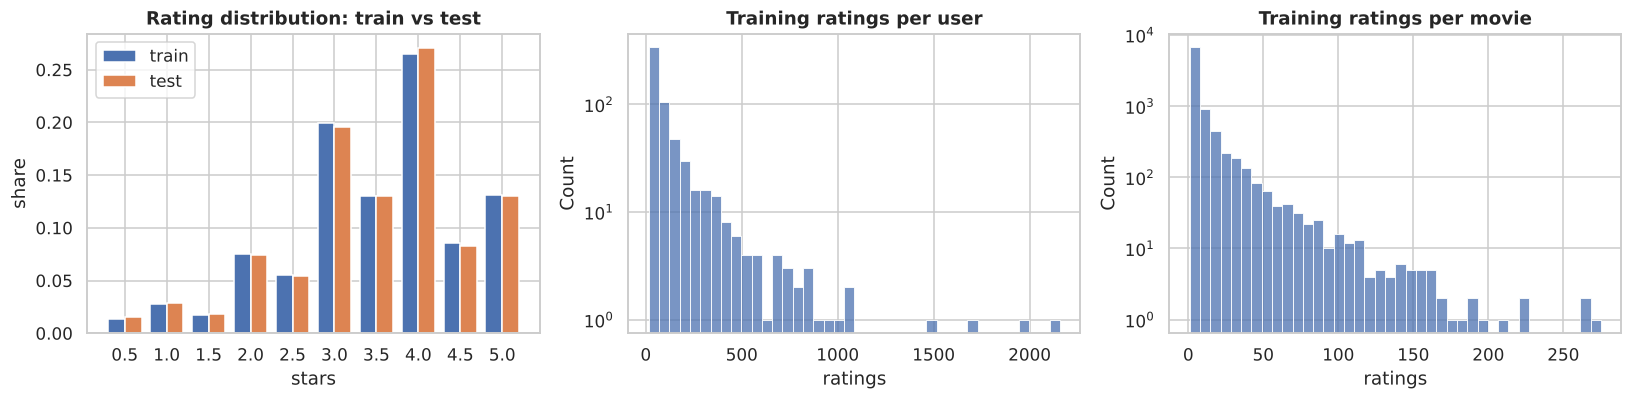

Median ratings/user: 56 | median ratings/movie: 2 | movies with >= 30 ratings: 704 of 8,995


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
order = np.sort(train.rating.unique())
tr_d = train.rating.value_counts(normalize=True).reindex(order); te_d = test.rating.value_counts(normalize=True).reindex(order)
x = np.arange(len(order)); axes[0].bar(x - .2, tr_d, .4, label='train', color='#4C72B0'); axes[0].bar(x + .2, te_d, .4, label='test', color='#DD8452')
axes[0].set_xticks(x); axes[0].set_xticklabels(order); axes[0].set(title='Rating distribution: train vs test', xlabel='stars', ylabel='share'); axes[0].legend()
sns.histplot(user_counts, bins=40, ax=axes[1], color='#4C72B0'); axes[1].set(title='Training ratings per user', xlabel='ratings', yscale='log')
sns.histplot(train_counts, bins=40, ax=axes[2], color='#4C72B0'); axes[2].set(title='Training ratings per movie', xlabel='ratings', yscale='log')
plt.tight_layout(); plt.show()
print(f'Median ratings/user: {user_counts.median():.0f} | median ratings/movie: {train_counts.median():.0f} | movies with >= {MIN_RATINGS} ratings: {(train_counts >= MIN_RATINGS).sum()} of {len(train_counts):,}')

**Reading the data checks.** The test ratings follow the same star distribution as training, so there is no distribution shift between the two. Activity is heavy-tailed: the median movie has only 2 training ratings and just 704 of 8,995 have the 30 needed to be recommended. **3.9 % of test pairs (790) involve a movie the model has never seen**, and they can only be predicted from the user's own tendencies. About **48 % of test ratings are "liked" (≥ 4)**, so the like/dislike question in Section 6 is well balanced.

## 2. Rebuild the models (Phase 3 settings, trained on `train` only)

Four predictors are scored on exactly the same test pairs:

* **Global mean**: the same number for everyone (the weakest sensible benchmark)
* **BaselineOnly**: global mean + user bias + movie bias (Phase 3's tough benchmark)
* **Item-based KNN** (`KNNBaseline`, `pearson_baseline`, k = 60): the runner-up
* **SVD** (150 factors, 30 epochs, lr 0.01, reg 0.1): the chosen final model

In [4]:
reader = Reader(rating_scale=(0.5, 5.0))
trainset = Dataset.load_from_df(train[['userId', 'movieId', 'rating']], reader).build_full_trainset()
MU = trainset.global_mean

def fit_models(trainset, svd_seed=RS):
    return {
        'Baseline': BaselineOnly(verbose=False).fit(trainset),
        'ItemKNN':  KNNBaseline(k=KNN_K, sim_options={'name': 'pearson_baseline', 'user_based': False}, verbose=False).fit(trainset),
        'SVD':      SVD(**{**SVD_PARAMS, 'random_state': svd_seed}).fit(trainset),
    }

t0 = time.time(); models = fit_models(trainset); print(f'Trained 3 models in {time.time() - t0:.1f}s | global mean = {MU:.3f}')

testset = list(test[['userId', 'movieId', 'rating']].itertuples(index=False, name=None))
def predict_table(models, testset):
    out = pd.DataFrame(testset, columns=['userId', 'movieId', 'actual'])
    out['Global mean'] = MU
    for name, m in models.items():
        out[name] = [p.est for p in m.test(testset)]
    return out

pred = predict_table(models, testset)
pred['movie_in_train'] = pred.movieId.isin(train.movieId)
pred['user_n'] = pred.userId.map(user_counts)
pred['movie_n'] = pred.movieId.map(train_counts).fillna(0).astype(int)
MODEL_NAMES = ['Global mean', 'Baseline', 'ItemKNN', 'SVD']
pred.head()

Trained 3 models in 3.5s | global mean = 3.503


,userId,movieId,actual,Global mean,Baseline,ItemKNN,SVD,movie_in_train,user_n,movie_n
0,1,3578,5.0,3.502721,4.585090,4.577884,4.597674,True,186,136
1,1,1127,4.0,3.502721,4.270962,4.360133,4.256803,True,186,49
2,1,157,5.0,3.502721,3.928313,3.644673,3.702317,True,186,8
3,1,2617,2.0,3.502721,3.996449,3.973077,3.987261,True,186,65
4,1,260,5.0,3.502721,4.905955,5.000000,4.977438,True,186,210


### 1.1 Consistency checks against Phase 3

Before evaluating anything, three checks confirm this notebook is working from the same data and model as Phase 3:

1. The files have the sizes Phase 3 asserts and the same cold-start count it reported (790).
2. Re-running Phase 3's 5-fold cross-validation (same folds, same settings) reproduces its reported scores.
3. The retrained SVD gives the same top-5 list for user 86 as Phase 3's saved output.

In [5]:
from surprise.model_selection import cross_validate, KFold
assert len(train) == 80_672 and len(test) == 20_164 and train.userId.nunique() == 610 and test.userId.nunique() == 610
assert (~test.movieId.isin(train.movieId)).sum() == 790
n_user = pd.concat([train, test]).groupby('userId').size()
assert (test.groupby('userId').size().reindex(n_user.index) == np.round(0.2 * n_user)).all()     # Phase 2 rule: round(20%) per user
print('Sizes, 610 users, 790 cold-start test pairs and the per-user 20% rule all match Phase 3 / Phase 2.')

folds = KFold(n_splits=5, random_state=RS, shuffle=True); data = Dataset.load_from_df(train[['userId', 'movieId', 'rating']], reader)
chk = []
for name, algo, ref in [('BaselineOnly', BaselineOnly(verbose=False), 0.875), ('SVD (tuned)', SVD(**SVD_PARAMS), 0.860)]:
    r_ = cross_validate(algo, data, measures=['RMSE'], cv=folds, n_jobs=1); chk.append({'model': name, 'Phase 3 reported CV RMSE': ref, 'reproduced here': r_['test_rmse'].mean()})
display(pd.DataFrame(chk).style.format({'reproduced here': '{:.4f}'}).hide(axis='index'))

tc = train.groupby('movieId').size(); el = tc[tc >= MIN_RATINGS].index; seen = set(train.loc[train.userId == 86, 'movieId'])
top86 = [m for m, _ in sorted([(m, models['SVD'].predict(86, m, clip=False).est) for m in el if m not in seen], key=lambda x: x[1], reverse=True)[:5]]
phase3_top86 = [899, 1276, 1233, 1252, 904]      # Singin' in the Rain, Cool Hand Luke, Das Boot, Chinatown, Rear Window (Phase 3 output)
print('User 86 top-5 identical to Phase 3 output:', top86 == phase3_top86, '->', [movies.loc[m, 'title'] for m in top86])

Sizes, 610 users, 790 cold-start test pairs and the per-user 20% rule all match Phase 3 / Phase 2.


model,Phase 3 reported CV RMSE,reproduced here
BaselineOnly,0.875000,0.8745
SVD (tuned),0.860000,0.8603


User 86 top-5 identical to Phase 3 output: True -> ["Singin' in the Rain (1952)", 'Cool Hand Luke (1967)', 'Boot, Das (Boat, The) (1981)', 'Chinatown (1974)', 'Rear Window (1954)']


## 3. Rating-prediction accuracy on the held-out test set

**RMSE** (root mean squared error, punishes big misses) and **MAE** (mean absolute error) are both in *stars*. Because the test set is a finite sample, every score gets a **95 % bootstrap confidence interval** (1,000 resamples of the 20,164 test pairs). Differences between models are tested with a **paired bootstrap**, since all models are scored on the same pairs.

In [6]:
rng = np.random.default_rng(RS)
B = 1000
IDX = rng.integers(0, len(pred), size=(B, len(pred)))      # shared resamples -> paired comparisons

def rmse_of(e): return float(np.sqrt(np.mean(e ** 2)))
err = {m: pred[m].values - pred.actual.values for m in MODEL_NAMES}

rows = []
for m in MODEL_NAMES:
    e = err[m]
    b_rmse = np.sqrt((e[IDX] ** 2).mean(1)); b_mae = np.abs(e[IDX]).mean(1)
    rows.append({'model': m, 'RMSE': rmse_of(e), 'RMSE 95% CI': f'[{np.percentile(b_rmse, 2.5):.3f}, {np.percentile(b_rmse, 97.5):.3f}]',
                 'MAE': np.abs(e).mean(), 'MAE 95% CI': f'[{np.percentile(b_mae, 2.5):.3f}, {np.percentile(b_mae, 97.5):.3f}]',
                 'within 0.5 star': (np.abs(e) <= 0.5).mean(), 'within 1 star': (np.abs(e) <= 1).mean(),
                 'RMSE_lo': np.percentile(b_rmse, 2.5), 'RMSE_hi': np.percentile(b_rmse, 97.5)})
acc = pd.DataFrame(rows).set_index('model')
base_rmse = acc.loc['Baseline', 'RMSE']
acc['RMSE gain vs Baseline'] = 1 - acc.RMSE / base_rmse
acc['RMSE gain vs Global mean'] = 1 - acc.RMSE / acc.loc['Global mean', 'RMSE']
display(acc.drop(columns=['RMSE_lo', 'RMSE_hi']).style.format({'RMSE': '{:.4f}', 'MAE': '{:.4f}', 'within 0.5 star': '{:.1%}', 'within 1 star': '{:.1%}',
        'RMSE gain vs Baseline': '{:+.1%}', 'RMSE gain vs Global mean': '{:+.1%}'}))

,RMSE,RMSE 95% CI,MAE,MAE 95% CI,within 0.5 star,within 1 star,RMSE gain vs Baseline,RMSE gain vs Global mean
model,,,,,,,,
Global mean,1.0498,"[1.039, 1.061]",0.8307,"[0.821, 0.840]",40.0%,68.0%,-18.7%,+0.0%
Baseline,0.8840,"[0.874, 0.895]",0.6797,"[0.672, 0.687]",47.0%,77.0%,+0.0%,+15.8%
ItemKNN,0.8618,"[0.851, 0.873]",0.6562,"[0.648, 0.664]",48.9%,78.5%,+2.5%,+17.9%
SVD,0.8745,"[0.864, 0.885]",0.6669,"[0.659, 0.675]",47.9%,77.9%,+1.1%,+16.7%


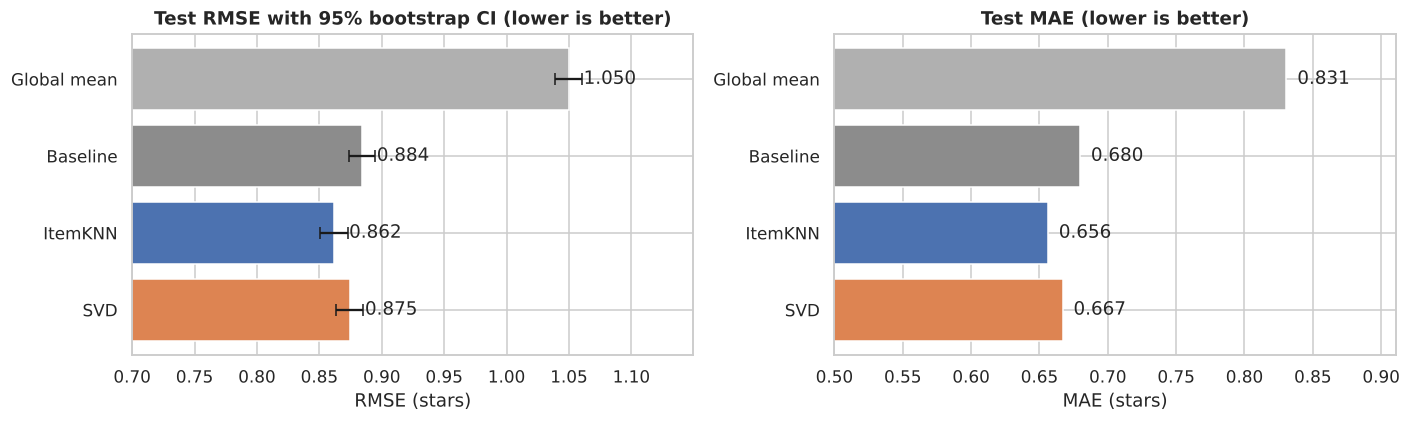

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
a = acc.loc[MODEL_NAMES]
axes[0].barh(a.index[::-1], a.RMSE[::-1], xerr=[(a.RMSE - a.RMSE_lo)[::-1], (a.RMSE_hi - a.RMSE)[::-1]], color=[COLORS[m] for m in a.index[::-1]], capsize=4)
for i, v in enumerate(a.RMSE[::-1]): axes[0].text(v + .012, i, f'{v:.3f}', va='center')
axes[0].set(xlim=(0.7, a.RMSE.max() + .1), title='Test RMSE with 95% bootstrap CI (lower is better)', xlabel='RMSE (stars)')
axes[1].barh(a.index[::-1], a.MAE[::-1], color=[COLORS[m] for m in a.index[::-1]])
for i, v in enumerate(a.MAE[::-1]): axes[1].text(v + .008, i, f'{v:.3f}', va='center')
axes[1].set(xlim=(0.5, a.MAE.max() + .08), title='Test MAE (lower is better)', xlabel='MAE (stars)')
plt.tight_layout(); plt.show()

### 3.1 Is the difference between models real? (paired bootstrap and Wilcoxon test)

comparison,RMSE diff,95% CI,P(a better),MAE diff,Wilcoxon p (|error|)
SVD minus Baseline,-0.0095,"[-0.0124, -0.0066]",100.0%,-0.0127,3.65e-24
ItemKNN minus Baseline,-0.0222,"[-0.0261, -0.0186]",100.0%,-0.0235,6.57e-60
SVD minus ItemKNN,+0.0127,"[+0.0086, +0.0168]",0.0%,+0.0107,2.93e-10


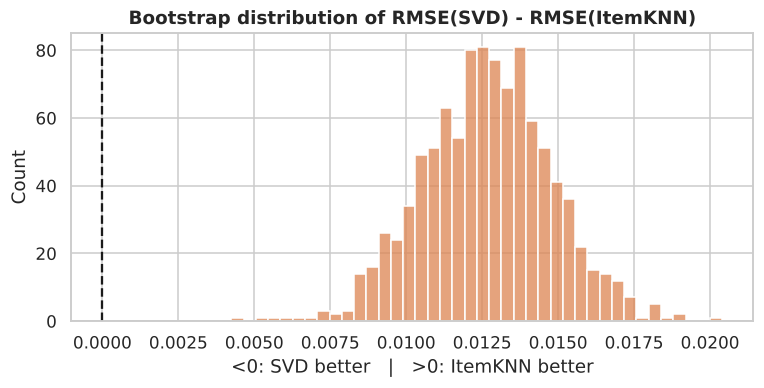

In [8]:
def paired(a, b):
    ea, eb = err[a], err[b]
    d = np.sqrt((ea[IDX] ** 2).mean(1)) - np.sqrt((eb[IDX] ** 2).mean(1))      # negative -> a is better
    w = stats.wilcoxon(np.abs(ea), np.abs(eb))
    return {'comparison': f'{a} minus {b}', 'RMSE diff': rmse_of(ea) - rmse_of(eb),
            '95% CI': f'[{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]',
            'P(a better)': float((d < 0).mean()), 'MAE diff': np.abs(ea).mean() - np.abs(eb).mean(), 'Wilcoxon p (|error|)': w.pvalue}
pairs = pd.DataFrame([paired('SVD', 'Baseline'), paired('ItemKNN', 'Baseline'), paired('SVD', 'ItemKNN')])
display(pairs.style.format({'RMSE diff': '{:+.4f}', 'P(a better)': '{:.1%}', 'MAE diff': '{:+.4f}', 'Wilcoxon p (|error|)': '{:.2e}'}).hide(axis='index'))

d_svd_knn = np.sqrt((err['SVD'][IDX] ** 2).mean(1)) - np.sqrt((err['ItemKNN'][IDX] ** 2).mean(1))
fig, ax = plt.subplots(figsize=(8, 3.4))
sns.histplot(d_svd_knn, bins=40, color='#DD8452', ax=ax); ax.axvline(0, color='k', ls='--')
ax.set(title='Bootstrap distribution of RMSE(SVD) - RMSE(ItemKNN)', xlabel='<0: SVD better   |   >0: ItemKNN better'); plt.show()

### 3.2 Did Phase 3's cross-validation estimate carry over to the test set?

model,Phase 3 CV RMSE,Test RMSE,gap (test - CV)
Baseline,0.875,0.8840,+0.0090
ItemKNN,0.862,0.8618,-0.0002
SVD,0.860,0.8745,+0.0145


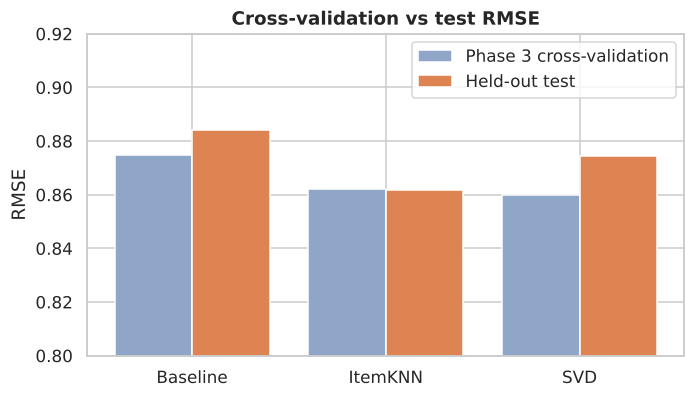

In [9]:
gen = pd.DataFrame([{'model': n, 'Phase 3 CV RMSE': PHASE3_CV[k][0], 'Test RMSE': acc.loc[n, 'RMSE']}
                    for n, k in [('Baseline', 'BaselineOnly'), ('ItemKNN', 'ItemKNN'), ('SVD', 'SVD')]])
gen['gap (test - CV)'] = gen['Test RMSE'] - gen['Phase 3 CV RMSE']
display(gen.style.format({'Phase 3 CV RMSE': '{:.3f}', 'Test RMSE': '{:.4f}', 'gap (test - CV)': '{:+.4f}'}).hide(axis='index'))

fig, ax = plt.subplots(figsize=(7, 3.8)); x = np.arange(len(gen))
ax.bar(x - .2, gen['Phase 3 CV RMSE'], .4, label='Phase 3 cross-validation', color='#8FA6C9'); ax.bar(x + .2, gen['Test RMSE'], .4, label='Held-out test', color='#DD8452')
ax.set_xticks(x); ax.set_xticklabels(gen.model); ax.set(ylim=(0.8, 0.92), title='Cross-validation vs test RMSE', ylabel='RMSE'); ax.legend(); plt.show()

### What Section 3 shows

* **The model learned real signal.** SVD cuts RMSE by about **17 %** versus the global mean. Most of that comes from knowing that *some users are generous* and *some movies are loved*: BaselineOnly already captures almost all of it. SVD's extra personalisation adds a further **1.1 % RMSE** (0.0095 stars; MAE −1.9 %). It is small, but the paired bootstrap interval [−0.0124, −0.0066] excludes zero, so it is a real effect.
* **Item-KNN is the most accurate model on the test set**: RMSE 0.8618 vs 0.8745 for SVD and MAE 0.656 vs 0.667. Phase 3 called the pair a tie on cross-validation (0.862 vs 0.860). On the test set the gap, 0.0127 with CI [+0.0086, +0.0168], is clearly not zero. Section 9 shows it is smaller on other splits (0.0043 on average) but points the same way every time, so the safe reading is *item-KNN is at least as accurate as SVD and probably a little better*.
* **Cross-validation versus test (3.2).** Item-KNN matched its cross-validation score. SVD finished 0.0145 above it and BaselineOnly 0.009 above. Because the baseline moved too, much of the shift is that this test set is harder than the folds used in cross-validation. Section 9 confirms that the provided split is tougher than five alternative draws of the same rule. There is no sign that tuning leaked into the test set, since that would make the test scores *better* than cross-validation, not worse.
* **Practical meaning.** A typical SVD prediction is off by about **0.67 stars** (MAE), roughly one rating step on a half-star scale. The table shows the share of predictions within half a star and within one full star.

## 4. Error diagnostics: how do the predictions go wrong?

A single RMSE hides the shape of the errors. These plots check whether errors are centred on zero, whether the model is **calibrated** (when it says 4.0, do users average 4.0?), and whether it systematically misjudges certain ratings.

Residual = predicted − actual. Positive means the model was too optimistic.

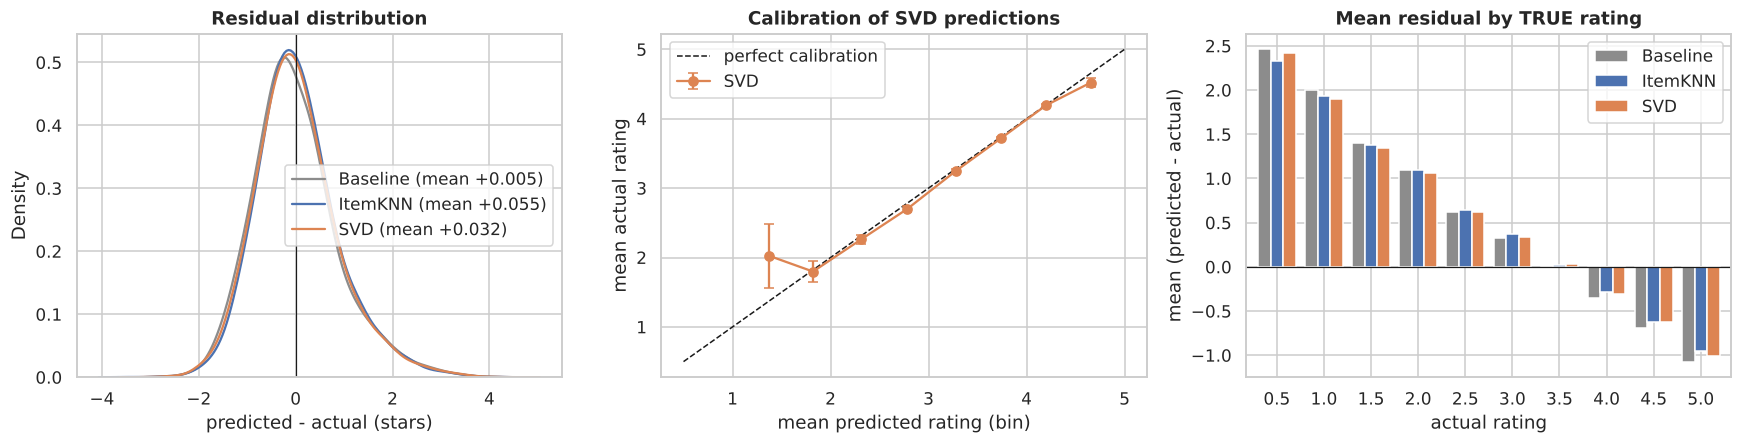

,mean_pred,mean_actual,n,se
bin,,,,
"(1.0, 1.5]",1.375,2.024,21,0.238
"(1.5, 2.0]",1.821,1.798,173,0.075
"(2.0, 2.5]",2.315,2.263,913,0.034
"(2.5, 3.0]",2.783,2.700,2414,0.020
"(3.0, 3.5]",3.278,3.247,5227,0.013
"(3.5, 4.0]",3.741,3.720,7277,0.010
"(4.0, 4.5]",4.199,4.193,3601,0.013
"(4.5, 5.0]",4.656,4.521,537,0.031


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for m in ['Baseline', 'ItemKNN', 'SVD']:
    sns.kdeplot(err[m], ax=axes[0], label=f'{m} (mean {err[m].mean():+.3f})', color=COLORS[m], bw_adjust=1.5)
axes[0].axvline(0, color='k', lw=.8); axes[0].set(title='Residual distribution', xlabel='predicted - actual (stars)'); axes[0].legend()

pred['bin'] = pd.cut(pred.SVD, np.arange(0.5, 5.51, .5), include_lowest=True)
cal = pred.groupby('bin', observed=True).agg(mean_pred=('SVD', 'mean'), mean_actual=('actual', 'mean'), n=('actual', 'size'),
                                              se=('actual', lambda s: s.std() / np.sqrt(len(s))))
cal = cal[cal.n >= 20]
axes[1].plot([0.5, 5], [0.5, 5], 'k--', lw=1, label='perfect calibration')
axes[1].errorbar(cal.mean_pred, cal.mean_actual, yerr=1.96 * cal.se, fmt='o-', color=COLORS['SVD'], capsize=3, label='SVD')
axes[1].set(title='Calibration of SVD predictions', xlabel='mean predicted rating (bin)', ylabel='mean actual rating'); axes[1].legend()

order = np.sort(pred.actual.unique())
bias_by_actual = pd.DataFrame({m: pd.Series(err[m]).groupby(pred.actual.values).mean() for m in ['Baseline', 'ItemKNN', 'SVD']})
bias_by_actual.plot(kind='bar', ax=axes[2], color=[COLORS[m] for m in bias_by_actual.columns], width=.8)
axes[2].axhline(0, color='k', lw=.8); axes[2].set(title='Mean residual by TRUE rating', xlabel='actual rating', ylabel='mean (predicted - actual)'); axes[2].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
display(cal.round(3))

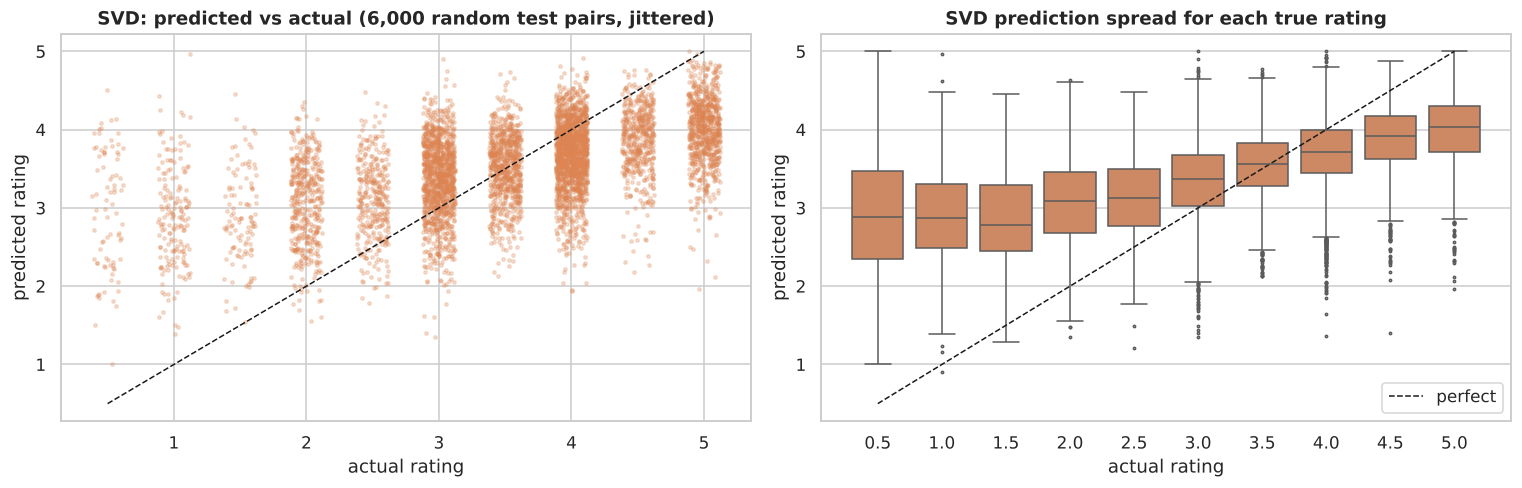

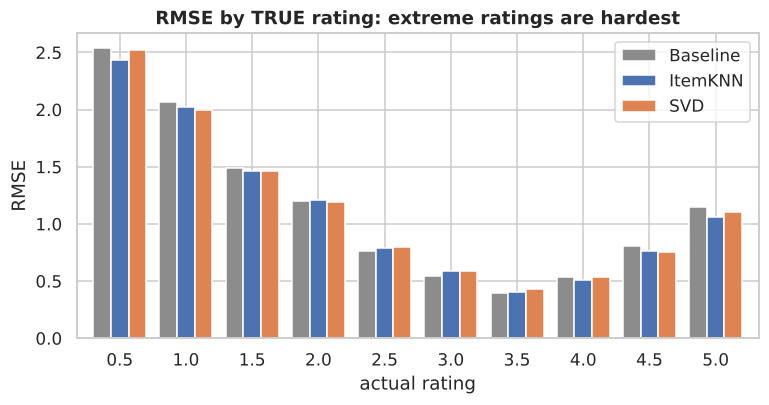

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
samp = pred.sample(6000, random_state=RS)
axes[0].scatter(samp.actual + np.random.default_rng(1).uniform(-.12, .12, len(samp)), samp.SVD, s=5, alpha=.25, color=COLORS['SVD'])
axes[0].plot([.5, 5], [.5, 5], 'k--', lw=1); axes[0].set(title='SVD: predicted vs actual (6,000 random test pairs, jittered)', xlabel='actual rating', ylabel='predicted rating')
sns.boxplot(data=pred, x='actual', y='SVD', ax=axes[1], color=COLORS['SVD'], fliersize=1.5)
axes[1].plot(range(len(order)), order, 'k--', lw=1, label='perfect'); axes[1].set(title='SVD prediction spread for each true rating', xlabel='actual rating', ylabel='predicted rating'); axes[1].legend()
plt.tight_layout(); plt.show()

rmse_by_actual = pd.DataFrame({m: pd.Series(err[m] ** 2).groupby(pred.actual.values).mean() ** .5 for m in ['Baseline', 'ItemKNN', 'SVD']})
fig, ax = plt.subplots(figsize=(8, 3.6)); rmse_by_actual.plot(kind='bar', ax=ax, color=[COLORS[m] for m in rmse_by_actual.columns], width=.8)
ax.set(title='RMSE by TRUE rating: extreme ratings are hardest', xlabel='actual rating', ylabel='RMSE'); ax.tick_params(axis='x', rotation=0); plt.show()

### What Section 4 shows

* **Errors are centred on zero** overall and the model is **well calibrated in the middle of the scale**: when SVD predicts about 3.7 the average actual rating is 3.72, and at 4.2 it is 4.19. Calibration drifts only at the extremes: predictions near 4.7 correspond to actual averages of 4.5, and the few predictions near 1.4 (21 pairs) to 2.0.
* **The model compresses the rating range ("regression to the mean").** A true 0.5-star rating is over-predicted by **+2.4 stars** and a true 5-star rating under-predicted by **−1.0 star**. The predictions for true 0.5-star and 5-star ratings overlap heavily with those for 3 stars (see the box plot). Ratings contain a lot of individual noise that no model can see, so the safest prediction sits near the centre. It does mean the model **cannot reliably spot movies a user will hate**, and the extreme ratings are where RMSE is highest.
* **All three models share this pattern.** The curves for Baseline, KNN and SVD are nearly identical, which is another sign that the personalised part adds little beyond averages.

### Within-user ordering (4.1)
The median per-user Spearman correlation between predicted and actual ratings is **0.401 for SVD, 0.378 for BaselineOnly and 0.430 for item-KNN**. Positive and meaningful, but SVD adds only about 0.02 over the baseline, and item-KNN more than twice as much. Ordering a person's movies is the thing a recommender exists to do, and most of that ordering still comes from "which movies are generally liked".

### 4.1 Within-user ordering

Recommendations only need the model to **rank** a user's movies correctly, so absolute accuracy is not the only thing that matters. For each user with at least 5 test ratings, this is the Spearman rank correlation between predicted and actual ratings over that user's test movies. A model that only knows "this movie is good, this user is generous" will score well on RMSE but poorly here.

Users with a defined correlation: 565


,Baseline,ItemKNN,SVD
mean,0.327,0.382,0.345
50%,0.378,0.430,0.401
std,0.333,0.305,0.325


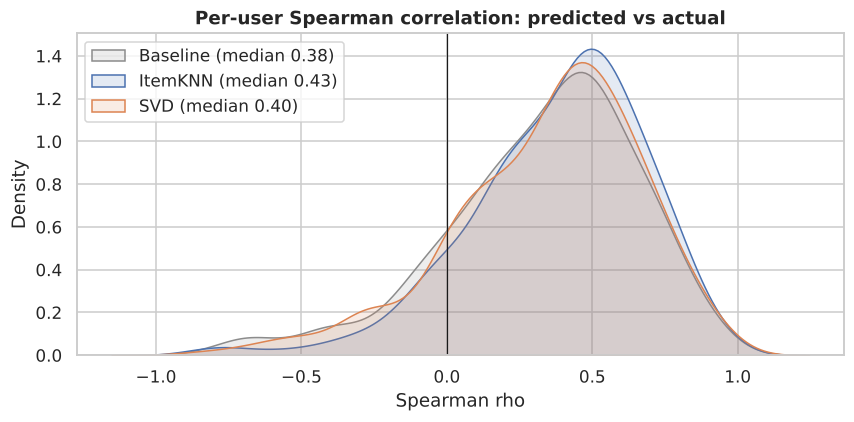

In [12]:
def user_spearman(col):
    g = pred.groupby('userId')
    return g.apply(lambda d: d.actual.corr(d[col], method='spearman') if len(d) >= 5 and d.actual.nunique() > 1 and d[col].nunique() > 1 else np.nan).dropna()
sp = pd.DataFrame({m: user_spearman(m) for m in ['Baseline', 'ItemKNN', 'SVD']})
print(f'Users with a defined correlation: {len(sp)}')
display(sp.describe().loc[['mean', '50%', 'std']].round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
for m in sp: sns.kdeplot(sp[m], ax=ax, label=f'{m} (median {sp[m].median():.2f})', color=COLORS[m], fill=True, alpha=.15)
ax.axvline(0, color='k', lw=.8); ax.set(title="Per-user Spearman correlation: predicted vs actual", xlabel='Spearman rho'); ax.legend(); plt.show()

## 5. Where does the model work and where does it struggle? (cold start)

### By how much data the user and movie have (the cold-start question)

,n_test,Baseline,ItemKNN,SVD,SVD gain vs Baseline
user_bin,,,,,
<=25,578,1.008,1.002,0.997,+1.1%
26-50,1478,0.894,0.872,0.881,+1.4%
51-100,2157,0.971,0.945,0.953,+1.8%
101-200,3584,0.898,0.878,0.886,+1.4%
200+,12367,0.856,0.833,0.850,+0.8%


,n_test,Baseline,ItemKNN,SVD,SVD gain vs Baseline
movie_bin,,,,,
unseen (0),790,1.041,1.041,1.028,+1.2%
1-4,2223,0.967,1.003,0.978,-1.2%
5-19,4864,0.860,0.855,0.854,+0.7%
20-49,5655,0.873,0.839,0.864,+1.1%
50-99,3922,0.878,0.832,0.861,+1.9%
100+,2710,0.835,0.776,0.811,+2.9%


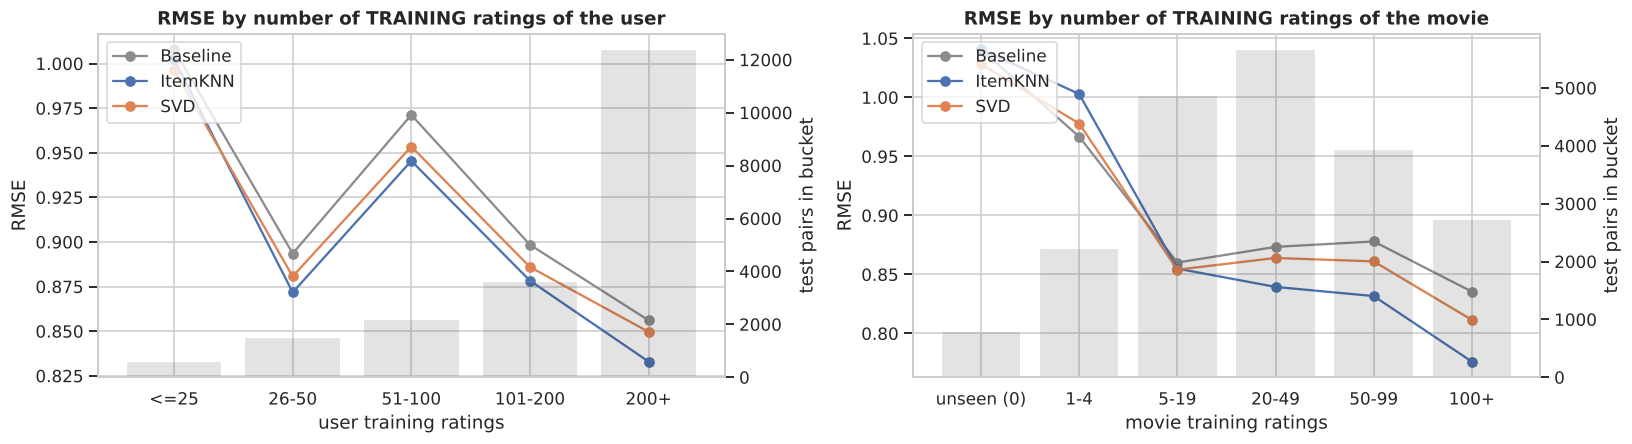

In [13]:
U_BINS = [0, 25, 50, 100, 200, np.inf]; U_LAB = ['<=25', '26-50', '51-100', '101-200', '200+']
M_BINS = [-1, 0, 4, 19, 49, 99, np.inf]; M_LAB = ['unseen (0)', '1-4', '5-19', '20-49', '50-99', '100+']
pred['user_bin'] = pd.cut(pred.user_n, U_BINS, labels=U_LAB)
pred['movie_bin'] = pd.cut(pred.movie_n, M_BINS, labels=M_LAB)
for m in ['Baseline', 'ItemKNN', 'SVD']: pred['se_' + m] = (pred[m] - pred.actual) ** 2

def seg(col):
    g = pred.groupby(col, observed=True)
    out = pd.DataFrame({'n_test': g.size(), **{m: np.sqrt(g['se_' + m].mean()) for m in ['Baseline', 'ItemKNN', 'SVD']}})
    out['SVD gain vs Baseline'] = 1 - out.SVD / out.Baseline
    return out
by_user, by_movie = seg('user_bin'), seg('movie_bin')
display(by_user.style.format({'Baseline': '{:.3f}', 'ItemKNN': '{:.3f}', 'SVD': '{:.3f}', 'SVD gain vs Baseline': '{:+.1%}'}))
display(by_movie.style.format({'Baseline': '{:.3f}', 'ItemKNN': '{:.3f}', 'SVD': '{:.3f}', 'SVD gain vs Baseline': '{:+.1%}'}))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for ax, df, t, xl in [(axes[0], by_user, 'RMSE by number of TRAINING ratings of the user', 'user training ratings'),
                      (axes[1], by_movie, 'RMSE by number of TRAINING ratings of the movie', 'movie training ratings')]:
    for m in ['Baseline', 'ItemKNN', 'SVD']: ax.plot(df.index.astype(str), df[m], 'o-', color=COLORS[m], label=m)
    ax2 = ax.twinx(); ax2.bar(df.index.astype(str), df.n_test, alpha=.12, color='k'); ax2.set_ylabel('test pairs in bucket'); ax2.grid(False)
    ax.set(title=t, xlabel=xl, ylabel='RMSE'); ax.legend(loc='upper left')
plt.tight_layout(); plt.show()

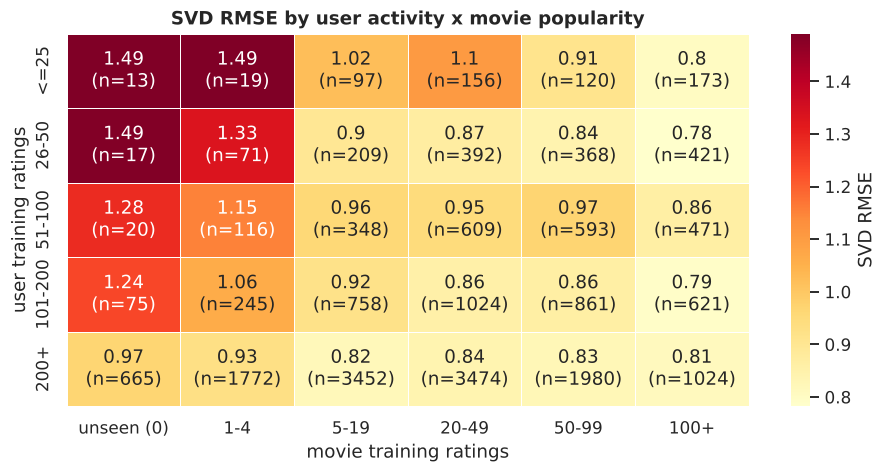

Cold-start movies: 790 test pairs (3.9%) | SVD RMSE 1.028 vs 0.868 on movies seen in training
Share of overall squared error that comes from cold-start movies: 5.4%
Distinct SVD predictions for cold-start movies: 150 (only user-level information is available)


In [14]:
heat = pred.pivot_table(index='user_bin', columns='movie_bin', values='se_SVD', aggfunc=lambda s: np.sqrt(s.mean()), observed=True)
cnt = pred.pivot_table(index='user_bin', columns='movie_bin', values='se_SVD', aggfunc='size', observed=True)
annot = heat.round(2).astype(str) + '\n(n=' + cnt.astype(str) + ')'
fig, ax = plt.subplots(figsize=(10, 4.4))
sns.heatmap(heat, annot=annot, fmt='', cmap='YlOrRd', ax=ax, cbar_kws={'label': 'SVD RMSE'}, linewidths=.5)
ax.set(title='SVD RMSE by user activity x movie popularity', xlabel='movie training ratings', ylabel='user training ratings'); plt.show()

cold = pred[~pred.movie_in_train]
print(f'Cold-start movies: {len(cold)} test pairs ({len(cold)/len(pred):.1%}) | SVD RMSE {np.sqrt(cold.se_SVD.mean()):.3f} vs {np.sqrt(pred[pred.movie_in_train].se_SVD.mean()):.3f} on movies seen in training')
print(f'Share of overall squared error that comes from cold-start movies: {cold.se_SVD.sum() / pred.se_SVD.sum():.1%}')
print(f'Distinct SVD predictions for cold-start movies: {cold.SVD.round(4).nunique()} (only user-level information is available)')

### What Section 5 shows

* **Movies the model has never seen** (3.9 % of test pairs, 790) have **RMSE 1.03** versus 0.87 for movies seen in training, and produce **5.4 %** of all squared error. SVD is slightly better than BaselineOnly there (1.028 vs 1.041), and item-KNN is identical to the baseline (it has no neighbours to use), but nothing can recover information that was never collected.
* **Movies with very few ratings** (1 to 4) are also poorly served: SVD is *worse* than BaselineOnly (0.978 vs 0.967) and item-KNN worse still (1.003). Personalisation needs data about the movie. SVD only pulls clearly ahead for popular movies (100+ ratings: 0.812 vs 0.835 for the baseline, a 2.9 % gain), and item-KNN is far better there (0.776).
* **Users with few ratings** are harder to predict (RMSE **0.997** for ≤ 25 ratings vs **0.850** for 200+). SVD's gain over BaselineOnly is modest in every group (0.8 % to 1.8 %). The heatmap shows the worst corner is a light user on a rarely-rated or unseen movie.
* Across almost every bucket **item-KNN has the lowest RMSE**.

## 6. Can the model tell what a user will *like*?

A recommender is judged by whether the movies it surfaces are enjoyed, not by decimal accuracy. Here every test rating is turned into a yes/no question: **"liked" = rating ≥ 4**. The predicted rating is the score, and a movie is predicted "liked" if its score clears a threshold.

* **ROC-AUC**: the chance that a randomly chosen liked movie scores higher than a randomly chosen disliked one (0.5 = coin flip)
* **PR-AUC (average precision)**: more informative when the classes are imbalanced. The no-skill line equals the share of liked movies.

,ROC-AUC,PR-AUC
Global mean,0.500,0.484
Baseline,0.775,0.750
ItemKNN,0.788,0.769
SVD,0.777,0.755


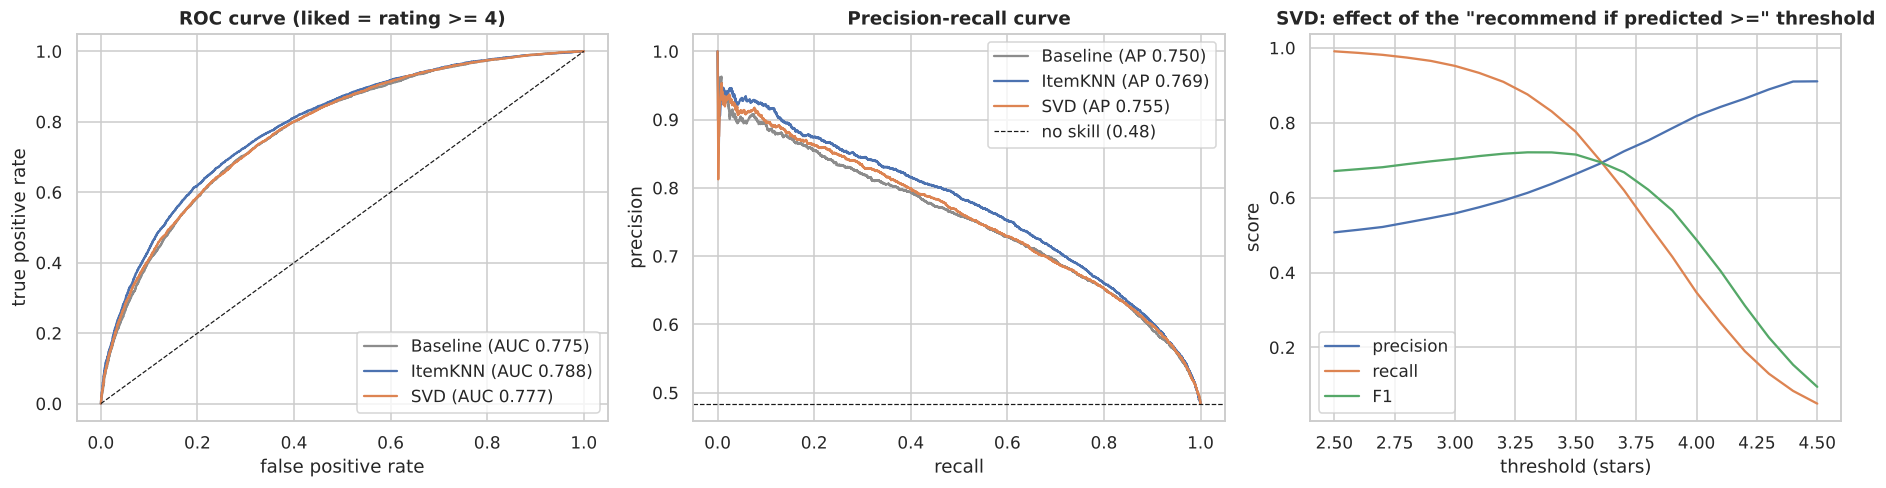

In [15]:
y = (pred.actual >= 4).astype(int).values
base_rate = y.mean()
clf = pd.DataFrame({m: {'ROC-AUC': roc_auc_score(y, pred[m]), 'PR-AUC': average_precision_score(y, pred[m])} for m in ['Global mean', 'Baseline', 'ItemKNN', 'SVD']}).T
clf.loc['Global mean'] = [0.5, base_rate]
display(clf.style.format('{:.3f}'))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for m in ['Baseline', 'ItemKNN', 'SVD']:
    fpr, tpr, _ = roc_curve(y, pred[m]); axes[0].plot(fpr, tpr, color=COLORS[m], label=f'{m} (AUC {clf.loc[m, "ROC-AUC"]:.3f})')
    p, r, _ = precision_recall_curve(y, pred[m]); axes[1].plot(r, p, color=COLORS[m], label=f'{m} (AP {clf.loc[m, "PR-AUC"]:.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=.8); axes[0].set(title='ROC curve (liked = rating >= 4)', xlabel='false positive rate', ylabel='true positive rate'); axes[0].legend(loc='lower right')
axes[1].axhline(base_rate, color='k', ls='--', lw=.8, label=f'no skill ({base_rate:.2f})'); axes[1].set(title='Precision-recall curve', xlabel='recall', ylabel='precision'); axes[1].legend(loc='upper right')

th = np.arange(2.5, 4.51, .1); res = []
for t in th:
    pr_ = pred.SVD.values >= t; tp = (pr_ & (y == 1)).sum(); p_ = tp / max(pr_.sum(), 1); r_ = tp / y.sum()
    res.append((t, p_, r_, 2 * p_ * r_ / max(p_ + r_, 1e-9)))
res = pd.DataFrame(res, columns=['threshold', 'precision', 'recall', 'F1'])
for c, col in [('precision', '#4C72B0'), ('recall', '#DD8452'), ('F1', '#55A868')]: axes[2].plot(res.threshold, res[c], color=col, label=c)
axes[2].set(title='SVD: effect of the "recommend if predicted >=" threshold', xlabel='threshold (stars)', ylabel='score'); axes[2].legend()
plt.tight_layout(); plt.show()

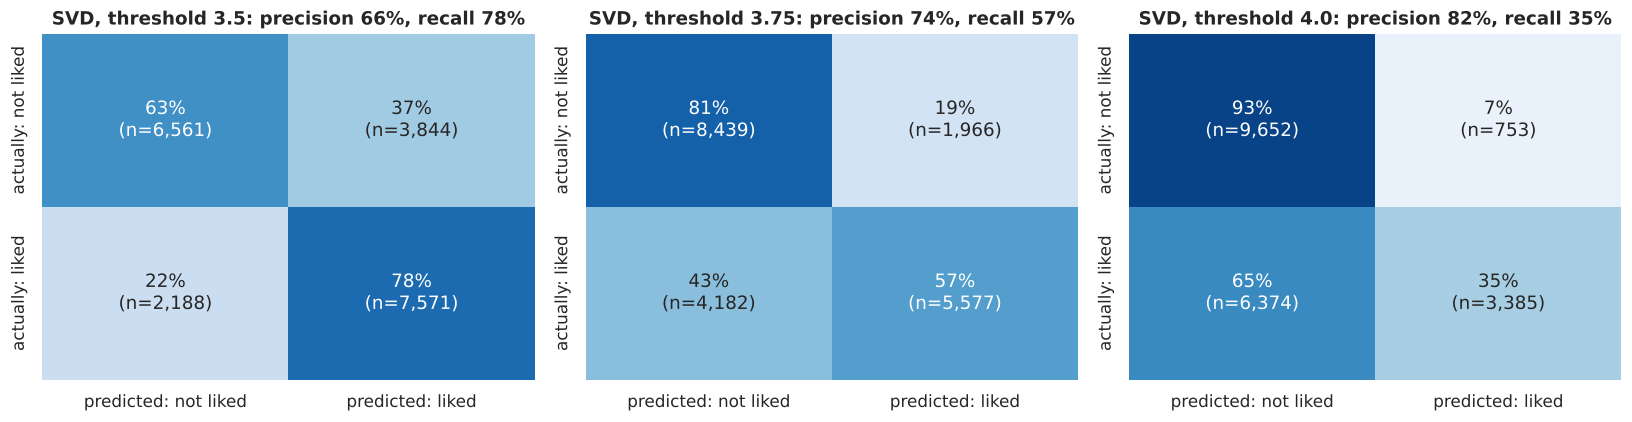

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, t in zip(axes, [3.5, 3.75, 4.0]):
    cm = confusion_matrix(y, (pred.SVD >= t).astype(int)); cmn = cm / cm.sum(1, keepdims=True)
    sns.heatmap(cmn, annot=[[f'{cmn[i, j]:.0%}\n(n={cm[i, j]:,})' for j in range(2)] for i in range(2)], fmt='', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['predicted: not liked', 'predicted: liked'], yticklabels=['actually: not liked', 'actually: liked'], vmin=0, vmax=1)
    p_ = cm[1, 1] / cm[:, 1].sum(); r_ = cm[1, 1] / cm[1].sum()
    ax.set_title(f'SVD, threshold {t}: precision {p_:.0%}, recall {r_:.0%}')
plt.tight_layout(); plt.show()

### What Section 6 shows

* **ROC-AUC = 0.777** for SVD: given one liked and one disliked movie, the model scores the liked one higher about 78 % of the time. It is far above a coin flip, but **BaselineOnly (0.775) is indistinguishable**. Item-KNN is a little higher (0.788). PR-AUC tells the same story (SVD 0.755, KNN 0.769, Baseline 0.750, against a no-skill level of 0.48).
* **The threshold trades precision for recall** (right-hand chart). A strict cut-off gives high precision but misses most of what the user would have liked. A lenient one finds most liked movies with more false alarms. Because recommendation is about *ranking* rather than a cut-off, treat the threshold as a dial for how cautious the list should be. It is not a property of the model.
* **Caution.** The threshold analysis is shown on the test set for illustration only. Selecting a threshold from these curves and then reporting the resulting score would be optimistic. A deployed system should choose the cut-off on validation data.

## 7. Evaluating the actual deliverable: the top-5 list

This mirrors `recommend_top5()` from Phase 3 for **every one of the 610 users**:

1. Candidates are movies with ≥ 30 training ratings that the user has not rated in training.
2. The model ranks the candidates and the top *K* are shown.
3. A recommendation is a **hit** if the user later rated that movie ≥ 4 in the held-out test set.

**How to read the numbers.** The test set only records movies the user *happened to rate*. A good recommendation the user never watched counts as a miss, so absolute precision is low for every model. What matters is the **comparison** with simple alternatives. Alongside the three CF models, three non-personalised rankers are included as yardsticks:

* **Popularity**: the most-rated movies
* **Top-rated**: highest damped average rating
* **Random**: a random eligible movie

Metrics: **Precision@K** (share of the K shown that were hits), **Recall@K** (share of the user's liked test movies found), **Hit rate@K** (users with at least one hit), **NDCG@K** (rewards hits near the top), **MAP@K**.

In [17]:
USERS = np.array(sorted(train.userId.unique()))
U_POS = {u: i for i, u in enumerate(USERS)}
IU = np.array([trainset.to_inner_uid(u) for u in USERS])

def score_matrix(name, items, seed=RS):
    ii = np.array([trainset.to_inner_iid(m) for m in items])
    if name == 'SVD':
        m = models['SVD']; return MU + m.bu[IU][:, None] + m.bi[ii][None, :] + m.pu[IU] @ m.qi[ii].T
    if name == 'Baseline':
        m = models['Baseline']; return MU + m.bu[IU][:, None] + m.bi[ii][None, :]
    if name == 'ItemKNN':
        m = models['ItemKNN']; return np.array([[m.predict(u, i, clip=False).est for i in items] for u in USERS])
    if name == 'Popularity':
        return np.tile(train_counts.reindex(items).values.astype(float), (len(USERS), 1))
    if name == 'Top-rated':
        s = train.groupby('movieId').rating.agg(['sum', 'count']).reindex(items); return np.tile(((s['sum'] + MU * 10) / (s['count'] + 10)).values, (len(USERS), 1))
    if name == 'Random':
        return np.random.default_rng(seed).random((len(USERS), len(items)))

def build_masks(items):
    pos = {m: i for i, m in enumerate(items)}
    seen = np.zeros((len(USERS), len(items)), bool); rel = np.zeros_like(seen)
    tr = train[train.movieId.isin(items)]; seen[tr.userId.map(U_POS).values, tr.movieId.map(pos).values] = True
    te = test[(test.rating >= 4) & test.movieId.isin(items)]; rel[te.userId.map(U_POS).values, te.movieId.map(pos).values] = True
    return seen, rel

def rank_eval(S, seen, rel, k_max=20, ties_seed=RS):
    S = np.where(seen, -np.inf, S + np.random.default_rng(ties_seed).random(S.shape) * 1e-9)   # tiny noise breaks exact ties fairly
    top = np.argsort(-S, axis=1)[:, :k_max]
    hits = np.take_along_axis(rel, top, 1).astype(float)
    n_rel = rel.sum(1); ok = n_rel > 0
    res = {'top': top, 'ok': ok}
    for k in (1, 3, 5, 10, 20):
        disc = 1 / np.log2(np.arange(2, k + 2)); h = hits[:, :k]
        idcg = np.cumsum(disc)[np.clip(np.minimum(n_rel, k) - 1, 0, None)]
        pk = np.cumsum(h, 1) / np.arange(1, k + 1)
        res[k] = {'precision': h.mean(1), 'recall': np.where(ok, h.sum(1) / np.maximum(n_rel, 1), np.nan),
                  'hit': (h.sum(1) > 0).astype(float), 'ndcg': np.where(ok, (h * disc).sum(1) / idcg, np.nan),
                  'map': np.where(ok, (pk * h).sum(1) / np.minimum(np.maximum(n_rel, 1), k), np.nan)}
    return res

ELIG = train_counts[train_counts >= MIN_RATINGS].index.values
SEEN, REL = build_masks(ELIG)
n_liked_test = (test.rating >= 4).sum()
print(f'Recommendable catalogue: {len(ELIG)} movies (>= {MIN_RATINGS} training ratings) out of {len(train_counts):,} rated movies')
print(f'Liked test ratings that fall on a recommendable movie: {REL.sum():,} of {n_liked_test:,} ({REL.sum() / n_liked_test:.1%}) -> upper bound on what any top-N list can reach')
print(f'Users with at least one liked, recommendable test movie: {(REL.sum(1) > 0).sum()} of {len(USERS)}')

RANKERS = ['Random', 'Popularity', 'Top-rated', 'Baseline', 'ItemKNN', 'SVD']
t0 = time.time()
SCORES = {n: score_matrix(n, ELIG) for n in RANKERS}
RANK = {n: rank_eval(SCORES[n], SEEN, REL) for n in RANKERS}
print(f'Scored {len(USERS)} users x {len(ELIG)} movies for {len(RANKERS)} rankers in {time.time() - t0:.0f}s')

Recommendable catalogue: 704 movies (>= 30 training ratings) out of 8,995 rated movies
Liked test ratings that fall on a recommendable movie: 5,695 of 9,759 (58.4%) -> upper bound on what any top-N list can reach
Users with at least one liked, recommendable test movie: 577 of 610


Scored 610 users x 704 movies for 6 rankers in 24s


,Precision@5,Recall@5,Hit rate@5,NDCG@5,MAP@5
Random,0.015,0.008,0.064,0.017,0.009
Popularity,0.131,0.077,0.416,0.160,0.104
Top-rated,0.088,0.042,0.292,0.108,0.068
Baseline,0.077,0.037,0.270,0.096,0.059
ItemKNN,0.095,0.040,0.302,0.106,0.067
SVD,0.087,0.047,0.303,0.100,0.059


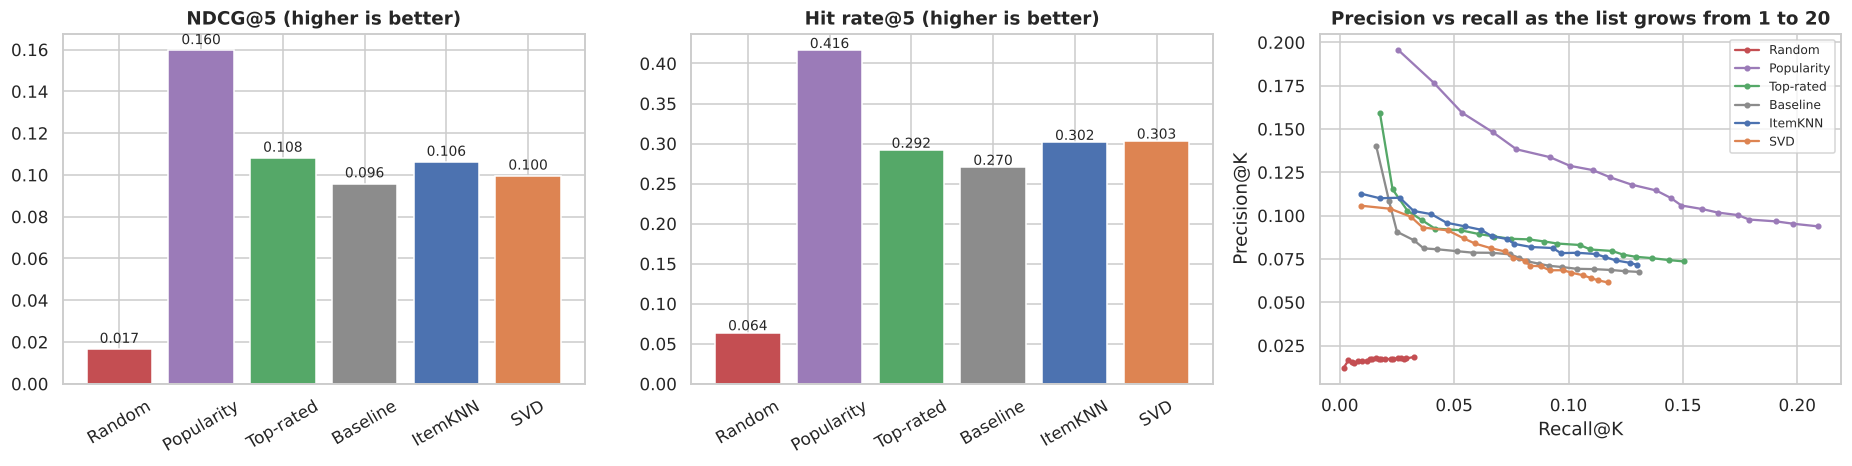

In [18]:
K = 5
tab = pd.DataFrame({n: {f'{mtr}@{K}': np.nanmean(RANK[n][K][mtr]) for mtr in ['precision', 'recall', 'hit', 'ndcg', 'map']} for n in RANKERS}).T
tab.columns = ['Precision@5', 'Recall@5', 'Hit rate@5', 'NDCG@5', 'MAP@5']
display(tab.style.format('{:.3f}').background_gradient(cmap='Greens', axis=0))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for ax, c in zip(axes[:2], ['NDCG@5', 'Hit rate@5']):
    v = tab[c].reindex(RANKERS); ax.bar(v.index, v.values, color=[COLORS[n] for n in v.index])
    for i, x_ in enumerate(v.values): ax.text(i, x_ + .003, f'{x_:.3f}', ha='center', fontsize=9)
    ax.set(title=f'{c} (higher is better)'); ax.tick_params(axis='x', rotation=30)
for n in RANKERS:
    ks = np.arange(1, 21); idx = np.argsort(-np.where(SEEN, -np.inf, SCORES[n] + np.random.default_rng(RS).random(SCORES[n].shape) * 1e-9), 1)[:, :20]
    h = np.take_along_axis(REL, idx, 1).astype(float); n_rel = REL.sum(1); ok = n_rel > 0
    axes[2].plot((np.cumsum(h[ok], 1) / n_rel[ok, None]).mean(0), (np.cumsum(h[ok], 1) / ks).mean(0), 'o-', ms=3, color=COLORS[n], label=n)
axes[2].set(title='Precision vs recall as the list grows from 1 to 20', xlabel='Recall@K', ylabel='Precision@K'); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 7.1 Is SVD's advantage in the top-5 list statistically solid? (bootstrap over users)

,NDCG@5,95% CI
ranker,,
Random,0.017,"[0.011, 0.023]"
Popularity,0.160,"[0.141, 0.180]"
Top-rated,0.108,"[0.093, 0.125]"
Baseline,0.096,"[0.082, 0.111]"
ItemKNN,0.106,"[0.090, 0.123]"
SVD,0.100,"[0.086, 0.114]"


comparison,mean NDCG@5 diff,95% CI,P(first better)
SVD - Popularity,-0.060,"[-0.076, -0.043]",0.0%
SVD - Top-rated,-0.009,"[-0.020, +0.004]",9.0%
SVD - Baseline,+0.004,"[-0.006, +0.015]",75.1%
SVD - ItemKNN,-0.007,"[-0.017, +0.005]",14.1%
ItemKNN - Baseline,+0.010,"[-0.002, +0.022]",95.4%


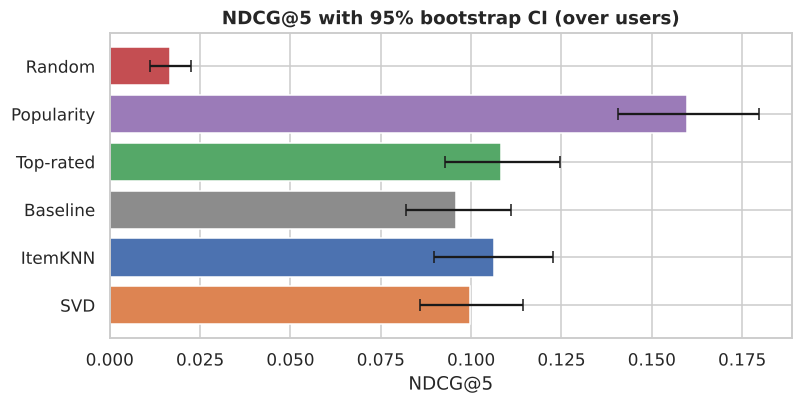

In [19]:
def user_metric(n, mtr, k=5):
    v = RANK[n][k][mtr]; return v[RANK[n]['ok']]
rngu = np.random.default_rng(RS); nu = RANK['SVD']['ok'].sum(); UIDX = rngu.integers(0, nu, size=(2000, nu))
rows = []
for n in RANKERS:
    v = user_metric(n, 'ndcg'); b = v[UIDX].mean(1); rows.append({'ranker': n, 'NDCG@5': v.mean(), '95% CI': f'[{np.percentile(b, 2.5):.3f}, {np.percentile(b, 97.5):.3f}]', 'lo': np.percentile(b, 2.5), 'hi': np.percentile(b, 97.5)})
nd = pd.DataFrame(rows).set_index('ranker'); display(nd[['NDCG@5', '95% CI']].style.format({'NDCG@5': '{:.3f}'}))

comp = []
for a, b_ in [('SVD', 'Popularity'), ('SVD', 'Top-rated'), ('SVD', 'Baseline'), ('SVD', 'ItemKNN'), ('ItemKNN', 'Baseline')]:
    d = user_metric(a, 'ndcg') - user_metric(b_, 'ndcg'); bd = d[UIDX].mean(1)
    comp.append({'comparison': f'{a} - {b_}', 'mean NDCG@5 diff': d.mean(), '95% CI': f'[{np.percentile(bd, 2.5):+.3f}, {np.percentile(bd, 97.5):+.3f}]', 'P(first better)': (bd > 0).mean()})
display(pd.DataFrame(comp).style.format({'mean NDCG@5 diff': '{:+.3f}', 'P(first better)': '{:.1%}'}).hide(axis='index'))

fig, ax = plt.subplots(figsize=(8, 3.6)); nd2 = nd.reindex(RANKERS)
ax.barh(nd2.index[::-1], nd2['NDCG@5'][::-1], xerr=[(nd2['NDCG@5'] - nd2.lo)[::-1], (nd2.hi - nd2['NDCG@5'])[::-1]], color=[COLORS[n] for n in nd2.index[::-1]], capsize=4)
ax.set(title='NDCG@5 with 95% bootstrap CI (over users)', xlabel='NDCG@5'); plt.show()

### 7.2 Does the hit rate depend on how active the user is?

,Popularity,Baseline,ItemKNN,SVD,users
<=25,0.072,0.033,0.015,0.029,96
26-50,0.097,0.042,0.036,0.043,158
51-100,0.126,0.072,0.069,0.076,118
101-200,0.183,0.091,0.115,0.124,103
200+,0.354,0.271,0.336,0.257,102


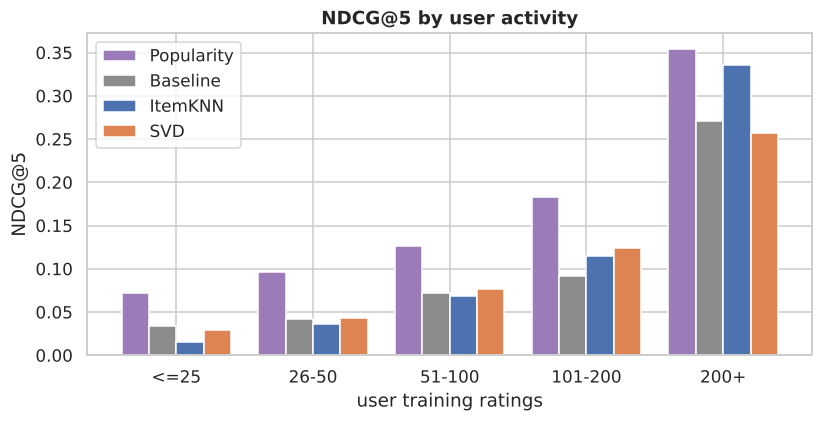

In [20]:
ok = RANK['SVD']['ok']; ubin = pd.cut(pd.Series(user_counts.reindex(USERS).values), U_BINS, labels=U_LAB)
seg_rank = pd.DataFrame({n: pd.Series(RANK[n][5]['ndcg']).groupby(ubin.values, observed=True).mean() for n in ['Popularity', 'Baseline', 'ItemKNN', 'SVD']})
seg_rank['users'] = pd.Series(ok).groupby(ubin.values, observed=True).sum()
display(seg_rank.round(3))
fig, ax = plt.subplots(figsize=(8.5, 3.8)); seg_rank.drop(columns='users').plot(kind='bar', ax=ax, color=[COLORS[n] for n in seg_rank.columns[:-1]], width=.8)
ax.set(title='NDCG@5 by user activity', xlabel='user training ratings', ylabel='NDCG@5'); ax.tick_params(axis='x', rotation=0); plt.show()

### What Section 7 shows (the most important section)

* **SVD's top-5 is better than random but not better than simple alternatives.** About **30 %** of users find at least one movie they later rated ≥ 4 among their five recommendations (random: 6 %). NDCG@5 is **0.100** vs **0.017** for random, about 6x.
* **A plain popularity list wins.** "Most-rated movies" scores NDCG@5 **0.160** and hit rate **42 %**. SVD is **0.060 NDCG lower**, with a CI of [−0.076, −0.043], so this is not noise. Popularity also leads in every user-activity group (7.2).
* **SVD, item-KNN and BaselineOnly cannot be separated** (NDCG@5 0.100 / 0.106 / 0.096, overlapping intervals, and every paired CI includes zero). Better rating accuracy for item-KNN did not translate into a statistically better top-5 list.
* **Why does popularity win?** (1) SVD's ranking leans heavily on each movie's average-quality bias, so it surfaces *highly rated* classics, which are not always the ones people *actually watch*. (2) The offline test only counts movies the user happened to rate, and people mostly rate popular movies, so **a popularity list is favoured by how the data was collected**. A good unseen suggestion counts as a miss. The result is therefore a warning, not proof that users would prefer popularity. An online or user test would be needed to settle it.
* **Heavier users get much better lists** (SVD NDCG@5 0.26 for 200+ ratings vs 0.03 for ≤ 25), again a data-quantity effect.
* **Upper bound.** Only 58 % of liked test ratings fall on movies with ≥ 30 training ratings, so even a perfect ranker could not reach the other 42 % under the current minimum-ratings rule.

## 8. Beyond accuracy: variety, popularity bias and personalisation

Phase 3 flagged that SVD tends to recommend well-loved classics to everyone, which clashes with the group's **objective 2 (variety)**. These metrics, computed on the same 610 top-5 lists, quantify that using only who was recommended what (no movie content such as genres):

| Metric | Meaning | Better |
|---|---|---|
| **Catalogue coverage** | share of the recommendable movies that appear in at least one list | higher |
| **Distinct movies** | number of different movies shown across all lists | higher |
| **Top-movie share** | share of users who get the single most-recommended movie | lower |
| **Gini of exposure** | inequality of how often movies are recommended (0 = equal, 1 = one movie gets everything) | lower |
| **Novelty** | average −log₂(popularity) of shown movies; higher = more of the long tail | higher |
| **Personalisation** | 1 − average overlap between two users' lists (0 = everyone gets the same list) | higher |

In [21]:
pop_share = (train_counts.reindex(ELIG) / len(USERS)).values

def beyond(n, k=5):
    top = RANK[n]['top'][:, :k]; flat = top.ravel(); cnt = np.bincount(flat, minlength=len(ELIG))
    R = np.zeros((len(USERS), len(ELIG))); np.put_along_axis(R, top, 1, 1)
    ov = (R @ R.T) / k; np.fill_diagonal(ov, np.nan)
    srt = np.sort(cnt); cum = np.cumsum(srt); gini = (len(srt) + 1 - 2 * (cum / cum[-1]).sum()) / len(srt)
    return {'Catalogue coverage': (cnt > 0).mean(), 'Distinct movies': int((cnt > 0).sum()), 'Top-movie share': cnt.max() / len(USERS),
            'Gini of exposure': gini, 'Novelty (bits)': float(-np.log2(pop_share[flat]).mean()), 'Mean popularity of picks': float(pop_share[flat].mean()),
            'Personalisation': 1 - np.nanmean(ov)}

bey = pd.DataFrame({n: beyond(n) for n in RANKERS}).T
display(bey.style.format({'Catalogue coverage': '{:.1%}', 'Top-movie share': '{:.1%}', 'Gini of exposure': '{:.3f}', 'Novelty (bits)': '{:.2f}',
                          'Mean popularity of picks': '{:.1%}', 'Personalisation': '{:.3f}', 'Distinct movies': '{:.0f}'}))

,Catalogue coverage,Distinct movies,Top-movie share,Gini of exposure,Novelty (bits),Mean popularity of picks,Personalisation
Random,98.6%,694,2.0%,0.273,3.60,9.2%,0.993
Popularity,4.7%,33,63.4%,0.986,1.47,36.6%,0.540
Top-rated,3.8%,27,83.8%,0.989,2.05,26.1%,0.405
Baseline,3.4%,24,87.7%,0.990,2.45,21.5%,0.343
ItemKNN,37.2%,262,28.0%,0.892,2.85,17.1%,0.911
SVD,19.0%,134,65.1%,0.954,2.90,17.5%,0.762


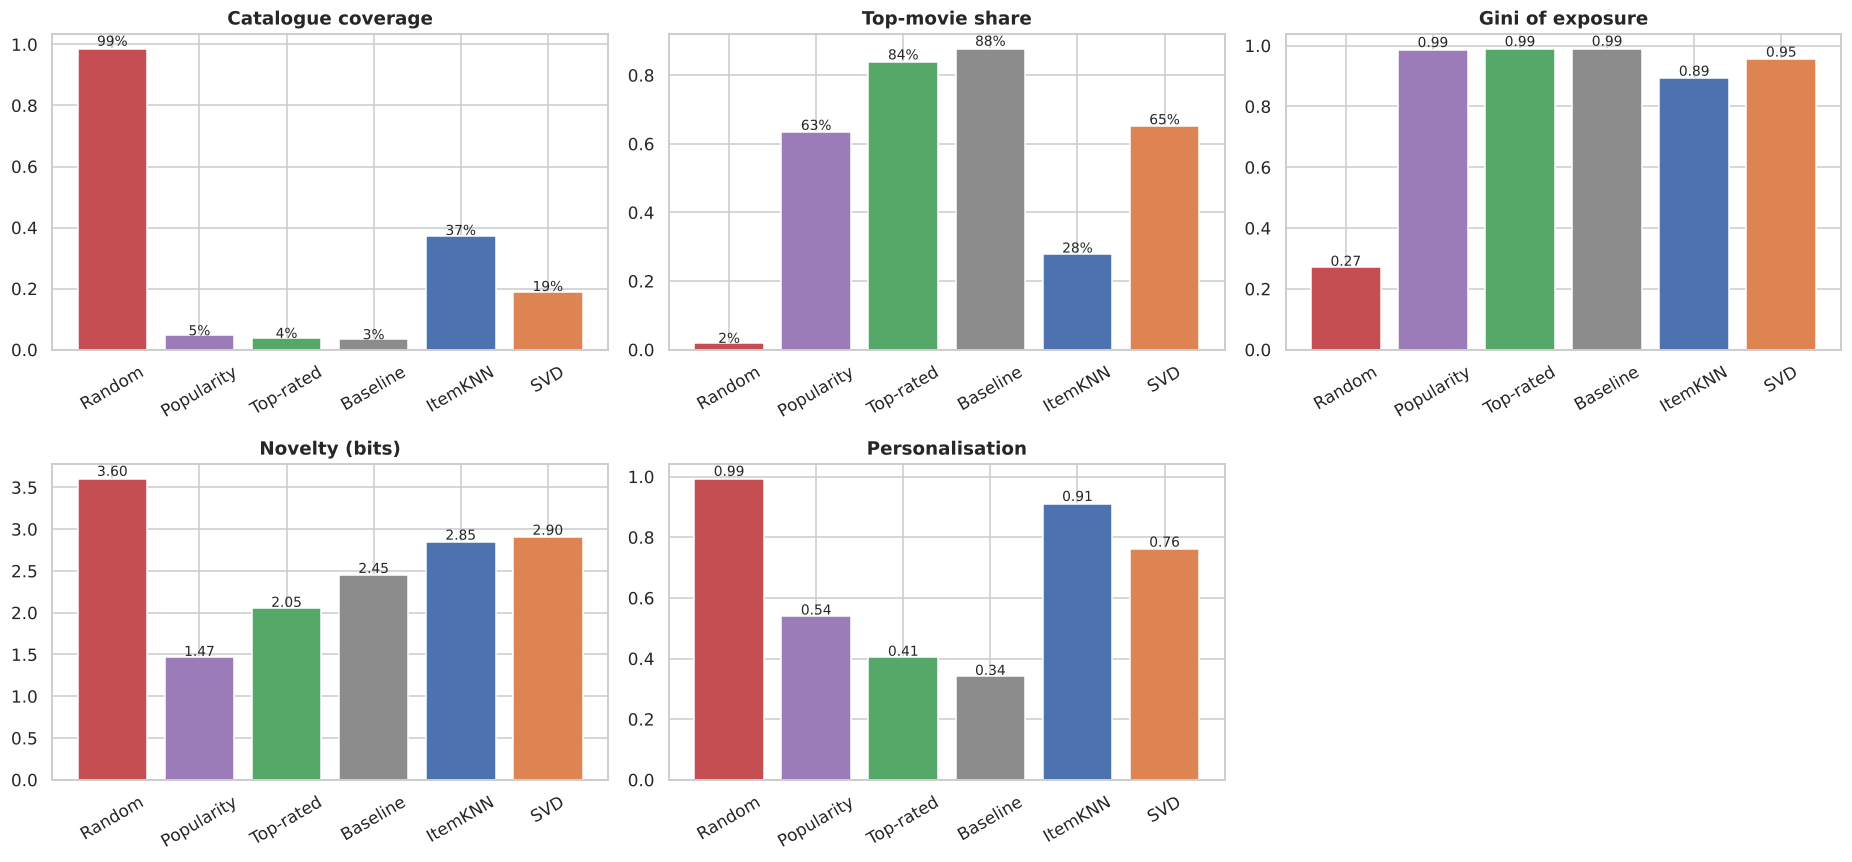

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8)); axes.ravel()[-1].axis('off')
for ax, c, fmt in zip(axes.ravel(), ['Catalogue coverage', 'Top-movie share', 'Gini of exposure', 'Novelty (bits)', 'Personalisation'],
                      ['{:.0%}', '{:.0%}', '{:.2f}', '{:.2f}', '{:.2f}']):
    v = bey[c].reindex(RANKERS); ax.bar(v.index, v.values, color=[COLORS[n] for n in v.index])
    for i, x_ in enumerate(v.values): ax.text(i, x_ * 1.01, fmt.format(x_), ha='center', fontsize=9)
    ax.set_title(c); ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

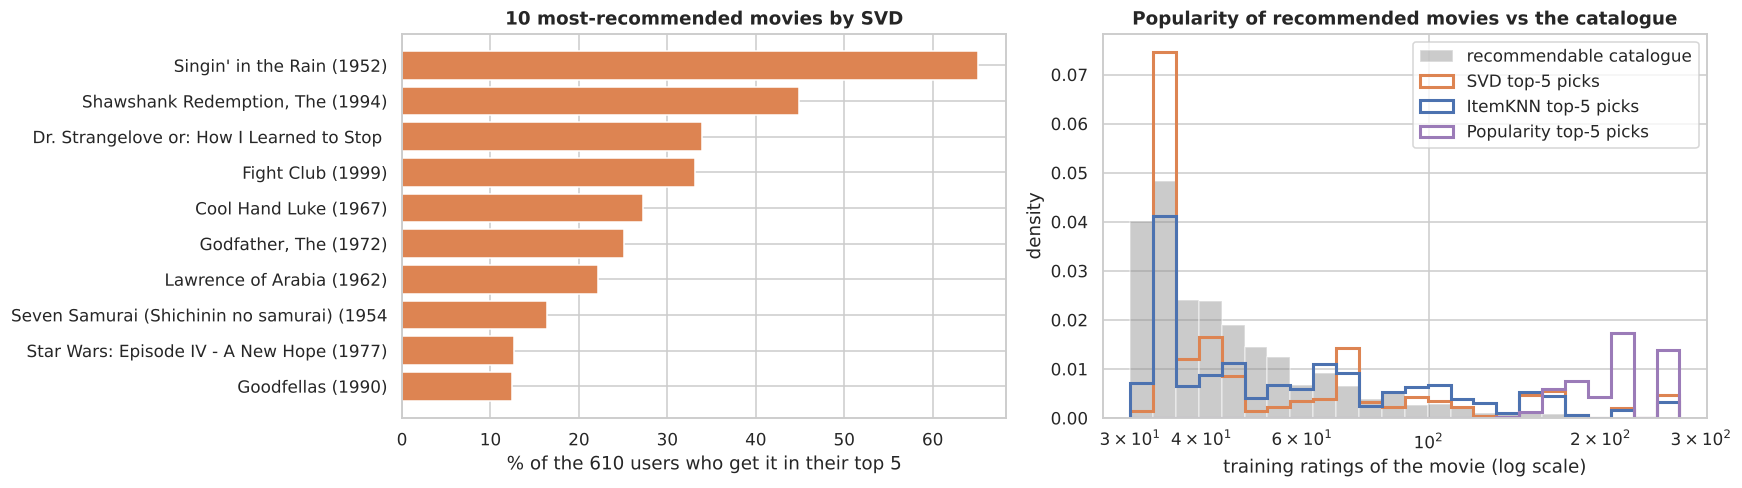

In [23]:
# What does SVD actually recommend, and how popular is it compared with the catalogue?
cnt = pd.Series(np.bincount(RANK['SVD']['top'][:, :5].ravel(), minlength=len(ELIG)), index=ELIG)
topm = cnt.sort_values(ascending=False).head(10)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
axes[0].barh([title[m][:42] for m in topm.index][::-1], (topm.values / len(USERS) * 100)[::-1], color=COLORS['SVD'])
axes[0].set(title='10 most-recommended movies by SVD', xlabel='% of the 610 users who get it in their top 5')
bins = np.logspace(np.log10(MIN_RATINGS), np.log10(train_counts.max()), 25)
axes[1].hist(train_counts.reindex(ELIG), bins=bins, alpha=.45, density=True, color='#8C8C8C', label='recommendable catalogue')
for n in ['SVD', 'ItemKNN', 'Popularity']:
    axes[1].hist(train_counts.reindex(ELIG).values[RANK[n]['top'][:, :5].ravel()], bins=bins, histtype='step', lw=2, density=True, color=COLORS[n], label=f'{n} top-5 picks')
axes[1].set(xscale='log', title='Popularity of recommended movies vs the catalogue', xlabel='training ratings of the movie (log scale)', ylabel='density'); axes[1].legend()
plt.tight_layout(); plt.show()

### 8.1 Sensitivity to the minimum-ratings rule (Phase 3's N = 30)

min_ratings,eligible movies,NDCG@5,Hit rate@5,distinct movies,top-movie share,reachable liked test items
10,1939,0.032,0.136,138,85%,81%
20,1051,0.058,0.198,139,56%,68%
30,704,0.100,0.303,134,65%,58%
50,312,0.143,0.357,103,49%,41%
100,82,0.215,0.379,52,53%,18%


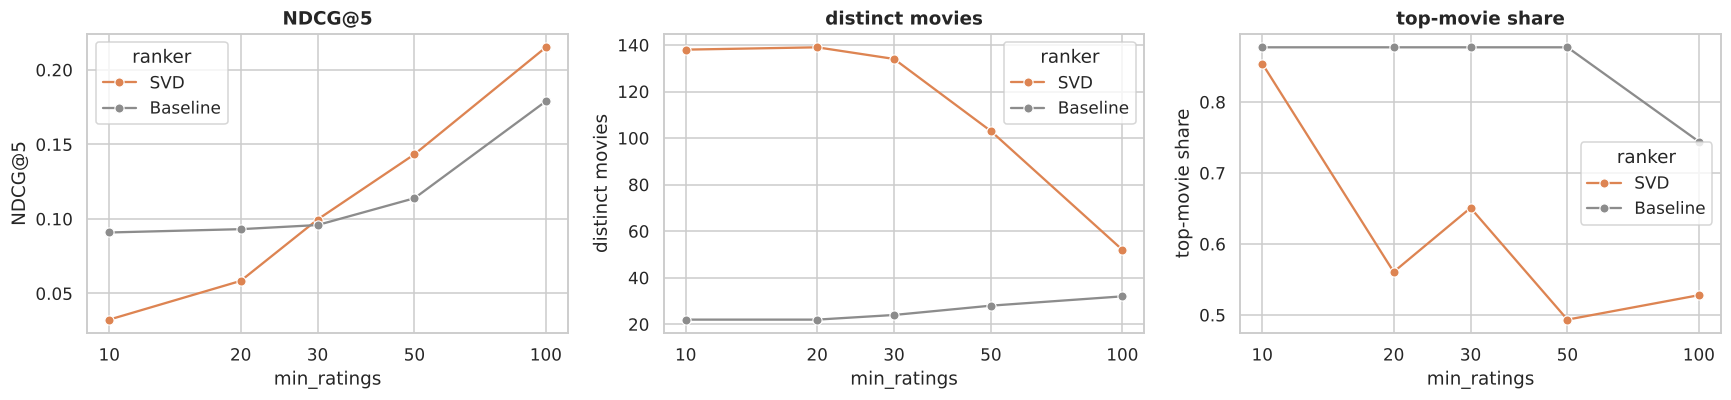

In [24]:
rows = []
for n_min in [10, 20, 30, 50, 100]:
    el = train_counts[train_counts >= n_min].index.values; sn, rl = build_masks(el)
    for n in ['SVD', 'Baseline']:
        S = score_matrix(n, el); r = rank_eval(S, sn, rl); ok_ = r['ok']
        top = r['top'][:, :5]; cnt_ = np.bincount(top.ravel(), minlength=len(el))
        rows.append({'min_ratings': n_min, 'ranker': n, 'eligible movies': len(el), 'NDCG@5': np.nanmean(r[5]['ndcg']), 'Hit rate@5': r[5]['hit'].mean(),
                     'distinct movies': int((cnt_ > 0).sum()), 'top-movie share': cnt_.max() / len(USERS), 'reachable liked test items': rl.sum() / n_liked_test})
sens = pd.DataFrame(rows); display(sens[sens.ranker == 'SVD'].drop(columns='ranker').style.format({'NDCG@5': '{:.3f}', 'Hit rate@5': '{:.3f}', 'top-movie share': '{:.0%}', 'reachable liked test items': '{:.0%}'}).hide(axis='index'))
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, c in zip(axes, ['NDCG@5', 'distinct movies', 'top-movie share']):
    sns.lineplot(data=sens, x='min_ratings', y=c, hue='ranker', marker='o', ax=ax, palette={'SVD': COLORS['SVD'], 'Baseline': COLORS['Baseline']}); ax.set(title=c, xscale='log'); ax.set_xticks([10, 20, 30, 50, 100]); ax.set_xticklabels([10, 20, 30, 50, 100])
plt.tight_layout(); plt.show()

### What Section 8 shows

| | SVD | Item-KNN | BaselineOnly | Popularity |
|---|---|---|---|---|
| Distinct movies shown (out of 704) | **134** | **262** | 24 | 33 |
| Users who get the #1 movie | **65 %** | 28 % | 88 % | 63 % |
| Personalisation (1 = different lists for everyone) | 0.76 | 0.91 | 0.34 | 0.54 |

* **SVD is personalised, but concentrated.** Its lists differ between users (0.76, far above BaselineOnly's 0.34 or Popularity's 0.54), yet they are drawn from only 19 % of the recommendable catalogue. *Singin' in the Rain* appears for 65 % of users, followed by *The Shawshank Redemption* (45 %) and *Dr. Strangelove* (34 %). Exposure inequality is high (Gini 0.95). This confirms Phase 3's warning, and shows that **objective 2 (variety) is not met**.
* **Item-KNN is the better-behaved recommender.** It reaches nearly twice as many different movies (262 vs 134), has a much lower top-movie share (28 %), higher personalisation (0.91), and the same top-5 quality as SVD. It is also more accurate (Sections 3 and 9). The price is a large movie-similarity table.
* **SVD's picks are not especially obscure or especially mainstream**: its novelty (2.91 bits) is similar to item-KNN's (2.85) and well above Popularity's (1.47). The concentration comes from a *few* very high-bias movies, not from a general preference for blockbusters.
* **The minimum-ratings rule (8.1).** Phase 3's N = 30 holds up. The number of distinct movies shown is essentially flat for N = 10, 20 and 30 (138, 139, 134), then falls to 103 at N = 50 and 52 at N = 100. Raising N also makes the headline NDCG rise (0.032 at N = 10 → 0.215 at N = 100), but only because the candidate pool shrinks to a handful of very popular movies: at N = 100 just 82 movies are eligible and only 18 % of liked test ratings are reachable. NDCG is therefore **not comparable across N**. A lower N would not buy more variety, and in fact at N = 10 the single top movie reaches 85 % of users. N = 30 is a reasonable compromise.

## 9. Robustness: would the conclusions survive a different split or random seed?

One split can flatter one model by luck. Here the whole pipeline is repeated on **5 different random per-user splits** (seeds 42 to 46), retraining all three models each time with the same Phase 3 settings, and SVD is also re-trained with **5 different initialisation seeds** on the main split.

model,Global mean,Baseline,ItemKNN,SVD,SVD - ItemKNN,SVD - Baseline
split_seed,,,,,,
42,1.0518,0.8759,0.8540,0.8596,0.0056,-0.0162
43,1.0402,0.8740,0.8525,0.8598,0.0073,-0.0142
44,1.0394,0.8728,0.8520,0.8554,0.0035,-0.0174
45,1.0407,0.8678,0.8471,0.8497,0.0026,-0.0181
46,1.0503,0.8822,0.8616,0.8640,0.0024,-0.0182


mean +/- std across splits:


model,Global mean,Baseline,ItemKNN,SVD,SVD - ItemKNN,SVD - Baseline
mean,1.0445,0.8745,0.8534,0.8577,0.0043,-0.0168
std,0.0061,0.0052,0.0052,0.0054,0.0021,0.0017


SVD beat ItemKNN (lower RMSE) on 0 of 5 splits; SVD beat BaselineOnly on 5 of 5 splits.


SVD initialisation seeds on the main split: RMSE 0.8738 +/- 0.0007 (range 0.8730 - 0.8747)


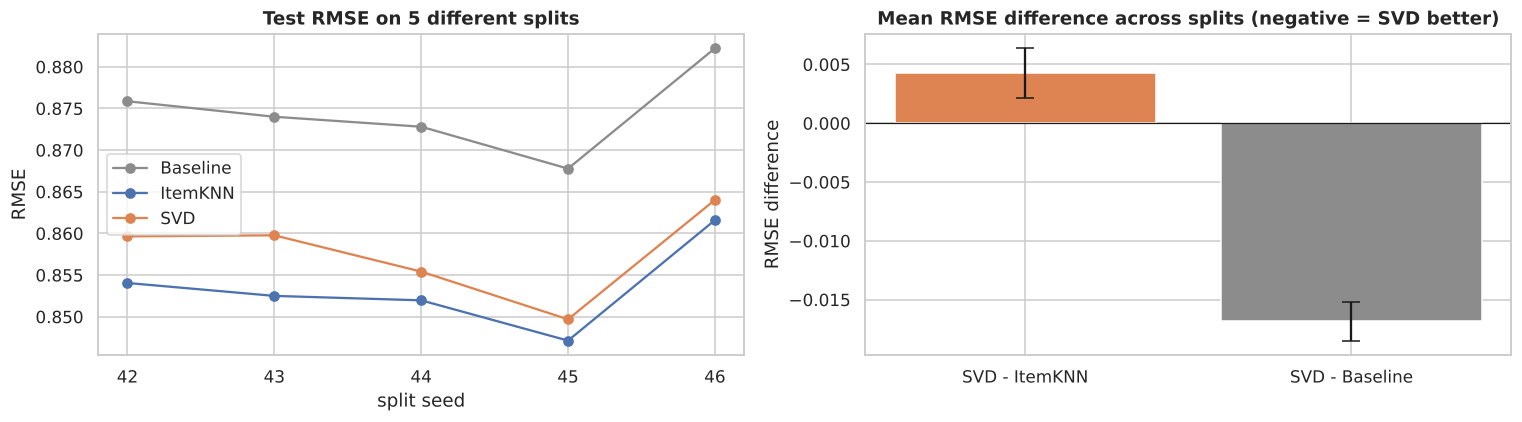

In [25]:
all_ratings = pd.concat([train, test[['userId', 'movieId', 'rating']]], ignore_index=True)    # same 100,836 ratings
rows = []
for seed in range(42, 47):
    trn, tst = per_user_split(all_ratings, seed=seed)
    ts = Dataset.load_from_df(trn, reader).build_full_trainset(); ms = fit_models(ts, svd_seed=seed)
    tl = list(tst.itertuples(index=False, name=None)); a_ = tst.rating.values
    for n, m in ms.items():
        e = np.array([p.est for p in m.test(tl)]) - a_; rows.append({'split_seed': seed, 'model': n, 'RMSE': rmse_of(e), 'MAE': np.abs(e).mean()})
    rows.append({'split_seed': seed, 'model': 'Global mean', 'RMSE': rmse_of(ts.global_mean - a_), 'MAE': np.abs(ts.global_mean - a_).mean()})
    del ms, ts; gc.collect()
rob = pd.DataFrame(rows)
piv = rob.pivot(index='split_seed', columns='model', values='RMSE')[['Global mean', 'Baseline', 'ItemKNN', 'SVD']]
piv['SVD - ItemKNN'] = piv.SVD - piv.ItemKNN; piv['SVD - Baseline'] = piv.SVD - piv.Baseline
display(piv.round(4)); print('mean +/- std across splits:'); display(piv.agg(['mean', 'std']).round(4))
print(f"SVD beat ItemKNN (lower RMSE) on {(piv['SVD - ItemKNN'] < 0).sum()} of 5 splits; SVD beat BaselineOnly on {(piv['SVD - Baseline'] < 0).sum()} of 5 splits.")

svd_seeds = []
for s in range(5):
    m = SVD(**{**SVD_PARAMS, 'random_state': 100 + s}).fit(trainset)
    svd_seeds.append(rmse_of(np.array([p.est for p in m.test(testset)]) - pred.actual.values))
print(f'SVD initialisation seeds on the main split: RMSE {np.mean(svd_seeds):.4f} +/- {np.std(svd_seeds):.4f} (range {min(svd_seeds):.4f} - {max(svd_seeds):.4f})')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for m in ['Baseline', 'ItemKNN', 'SVD']: axes[0].plot(piv.index, piv[m], 'o-', color=COLORS[m], label=m)
axes[0].set(title='Test RMSE on 5 different splits', xlabel='split seed', ylabel='RMSE'); axes[0].set_xticks(piv.index); axes[0].legend()
axes[1].bar(['SVD - ItemKNN', 'SVD - Baseline'], [piv['SVD - ItemKNN'].mean(), piv['SVD - Baseline'].mean()], yerr=[piv['SVD - ItemKNN'].std(), piv['SVD - Baseline'].std()], color=[COLORS['SVD'], COLORS['Baseline']], capsize=6)
axes[1].axhline(0, color='k', lw=.8); axes[1].set(title='Mean RMSE difference across splits (negative = SVD better)', ylabel='RMSE difference')
plt.tight_layout(); plt.show()

### What Section 9 shows

* **Seed noise is tiny.** Re-initialising SVD with five different seeds moves test RMSE by only ±0.0007.
* **Split noise is larger, and the provided test set is on the hard side.** Across five different random splits (same per-user 20 % rule) the mean test RMSE is Baseline **0.8745**, item-KNN **0.8534**, SVD **0.8577**, with a standard deviation of about 0.005 each. The provided `test.csv` gives higher numbers for all three models (0.884, 0.862, 0.8745), which explains most of the gap to cross-validation seen in Section 3.2.
* **The model ranking is stable.** SVD beats BaselineOnly on **5 of 5** splits (mean gain 0.017), and item-KNN beats SVD on **5 of 5** (mean 0.0043 ± 0.0021).
* **Conclusion.** "Personalised CF beats the baseline by about 1 to 2 % RMSE" is solid. "SVD is as accurate as item-KNN" is not supported: item-KNN is consistently, if modestly, ahead. This is consistent with Phase 3's tie being a statistical near-tie on cross-validation, and with item-KNN having a small real advantage.

## 10. Scorecard and verdict

In [26]:
score = pd.DataFrame({
    'Test RMSE': acc.RMSE, 'Test MAE': acc.MAE, 'ROC-AUC (liked)': clf['ROC-AUC'],
    'NDCG@5': tab['NDCG@5'], 'Hit rate@5': tab['Hit rate@5'],
    'Catalogue coverage': bey['Catalogue coverage'], 'Personalisation': bey['Personalisation'], 'Top-movie share': bey['Top-movie share'],
}).reindex(['Global mean', 'Baseline', 'ItemKNN', 'SVD', 'Popularity', 'Top-rated', 'Random'])
display(score.style.format({'Test RMSE': '{:.3f}', 'Test MAE': '{:.3f}', 'ROC-AUC (liked)': '{:.3f}', 'NDCG@5': '{:.3f}', 'Hit rate@5': '{:.3f}',
                            'Catalogue coverage': '{:.1%}', 'Personalisation': '{:.3f}', 'Top-movie share': '{:.0%}'}, na_rep='n/a')
        .background_gradient(cmap='RdYlGn_r', subset=['Test RMSE', 'Test MAE', 'Top-movie share']).background_gradient(cmap='RdYlGn', subset=['ROC-AUC (liked)', 'NDCG@5', 'Hit rate@5', 'Catalogue coverage', 'Personalisation']))

summary = {'test_rmse': acc.RMSE.round(4).to_dict(), 'test_mae': acc.MAE.round(4).to_dict(), 'ndcg5': tab['NDCG@5'].round(4).to_dict(), 'hit5': tab['Hit rate@5'].round(4).to_dict(),
           'auc': clf['ROC-AUC'].round(4).to_dict(), 'pr_auc': clf['PR-AUC'].round(4).to_dict(), 'beyond': bey.round(4).to_dict('index'),
           'pairs': pairs.round(5).to_dict('records'), 'cold': {'n': int(len(cold)), 'rmse_cold': float(np.sqrt(cold.se_SVD.mean())), 'err_share': float(cold.se_SVD.sum() / pred.se_SVD.sum())},
           'robust_mean': piv.mean().round(4).to_dict(), 'robust_std': piv.std().round(4).to_dict(), 'svd_seed_std': float(np.std(svd_seeds)),
           'by_user': by_user.round(4).to_dict('index'), 'by_movie': by_movie.round(4).to_dict('index'),
           'spearman_median': sp.median().round(3).to_dict(), 'gap': gen.round(4).to_dict('records'), 'base_rate': float(base_rate),
           'reach': float(REL.sum() / n_liked_test), 'n_elig': int(len(ELIG)), 'users_ok': int(RANK['SVD']['ok'].sum()),
           'cal': cal.round(3).to_dict('records'), 'bias_actual': bias_by_actual.round(3).to_dict(),
           'seg_rank': seg_rank.round(3).to_dict('index'), 'sens': sens.round(4).to_dict('records'), 'nd_ci': nd[['NDCG@5', 'lo', 'hi']].round(4).to_dict('index'),
           'comp': pd.DataFrame(comp).round(4).to_dict('records'),
           'top_recs': {title[m]: float(c / len(USERS)) for m, c in topm.items()}, 'svd_seeds': svd_seeds}
json.dump(summary, open('eval_summary.json', 'w'), default=float, indent=1)

,Test RMSE,Test MAE,ROC-AUC (liked),NDCG@5,Hit rate@5,Catalogue coverage,Personalisation,Top-movie share
Global mean,1.050,0.831,0.500,n/a,n/a,n/a,n/a,n/a
Baseline,0.884,0.680,0.775,0.096,0.270,3.4%,0.343,88%
ItemKNN,0.862,0.656,0.788,0.106,0.302,37.2%,0.911,28%
SVD,0.875,0.667,0.777,0.100,0.303,19.0%,0.762,65%
Popularity,n/a,n/a,n/a,0.160,0.416,4.7%,0.540,63%
Top-rated,n/a,n/a,n/a,0.108,0.292,3.8%,0.405,84%
Random,n/a,n/a,n/a,0.017,0.064,98.6%,0.993,2%


### Verdict

**Does the model meet the Phase 3 and project goals?**

| Goal | Verdict | Evidence |
|---|---|---|
| Predict ratings for unseen movies |  Met, modestly | RMSE 0.8745 / MAE 0.667 on 20,164 unseen pairs; beats the baseline on 5/5 splits |
| Reliable generalisation |  Mostly met | Test is 0.0145 above cross-validation for SVD, mostly because this split is harder than typical (Section 9); seed noise ±0.0007 |
| Useful top-5 recommendations |  Partially | ~6x random, but below a popularity list (NDCG@5 0.100 vs 0.160) and tied with BaselineOnly |
| **Objective 2: variety** |  Not met by SVD | 134 distinct movies; 65 % of users get the same #1 movie |
| Handle new users / new movies (cold start) |  Not handled | RMSE ≥ 1.0 for unseen movies and light users; the model falls back to averages |

### Recommended next steps (in order of expected value)

1. **Revisit the final model choice.** Item-KNN is more accurate on the test set (0.862 vs 0.8745) and on every alternative split, matches SVD on top-5 quality, and is much more varied (262 vs 134 movies, personalisation 0.91 vs 0.76). Phase 3 broke the tie on size and speed. This evaluation adds accuracy and variety as reasons to prefer KNN. Because the deliverable is a top-5 list per user, Julie can **precompute and store the lists**, so the similarity table need not ship with the app.
2. **Fix the ranking step rather than the rating model.** SVD's lists are dominated by each movie's overall-quality bias. Options worth testing, each cheap to try with the code in Section 7: rank by the *personal* part only (`pu · qi`) plus a small share of the bias; blend SVD scores with popularity; or re-rank the top 20 so no single movie can appear for too many users. Judge each with NDCG@5 **and** the Section 8 variety metrics together, since improving one alone is easy.
3. **Add a cold-start fallback.** Use a popularity-based list (or a blend of popularity and the model) for users with ≤ 25 ratings, and treat movies with fewer than 5 ratings separately, since the model has little to go on for either.
4. **Report ranking metrics as the headline.** RMSE moved only 1 to 2 % between models whose top-5 lists are very different. Precision/NDCG@5 and coverage should accompany RMSE in the project report.
5. **Run a small user or online check.** The popularity result is partly an artefact of how ratings are collected (Section 7). A short side-by-side test of SVD vs KNN vs popularity lists with real users would settle what offline data cannot.

## Limitations of this evaluation

* **Offline, observed-ratings-only.** Test data contains only movies users chose to rate. Unrated-but-good recommendations are scored as misses, which depresses all precision numbers and favours popularity. Relative comparisons are more trustworthy than absolute values.
* **One provided split.** The provided `test.csv` is a harder-than-typical draw (Section 9). Absolute scores would move by up to about ±0.01 RMSE on another draw, but the comparisons between models were stable across five alternatives.
* **"Liked" means rating ≥ 4.** A different cut-off would change the values in Sections 6 and 7, though not the ordering of the models in any check made here.
* **Bootstrap intervals** treat test ratings (Section 3) or users (Section 7) as independent samples. They are a guide to uncertainty, not an exact guarantee.
* **Only accuracy, variety and personalisation were measured, all from ratings data.** Serendipity, explanation quality and long-term user satisfaction need a live study.